# CSCI6032 Homework 7

**Instructions**

* **Insert all code, plots, results, and discussion** into this Jupyter Notebook.
* Your homework should be submitted as a **single Jupyter Notebook** (.ipynb file) to **Blackboard**.
* While working, you can use Visual Studio Code, Jupyter Notebook or Google Colab.  If using Google Colab, export it as a Jupyter Notebook (.ipynb).

You can answer mathematical questions either by:
* using LaTeX in a markdown cell, or
* handwriting your answer, then photographing or scanning it and using an AI/LLM to convert it into markdown and LaTeX, checking the conversion for accuracy before submitting.


---
## Problem 1: Logistic Regression, Compared with GDA and QDA

Implement logistic regression using only numpy and standard python libraries (pandas may be used to load the data and
matplotlib to plot it).  No usage of any existing implementation of logistic regression is allowed.

Logistic regression models the posterior probability directly,
$P(y=1 \mid \bar x)=\sigma(\bar w^T\bar x+b)$ with $\sigma(z)=1/(1+e^{-z})$, and learns $\bar w$ and $b$ by minimizing the
cross-entropy loss, for example by gradient descent.

Write your implementation so that it works on a whole batch of samples at once: a method that computes
$\hat{\bar y} = \sigma(X\bar w + b)$ for all rows of a data matrix $X$, and a method that computes the gradient of the average
cross-entropy loss.  You will derive this gradient in Problem 4.

This problem uses the data set and the training/test split from Homework 5.

**(a)** Apply the unit test from HW5 Problem 6(b) to the data set you created in HW5 Problem 6(a).  Confirm that logistic
regression achieves 100% accuracy on it. (4 points)

In [1]:
# ---------------------------------------------------------------------------
# Problem 1: logistic regression from scratch.  numpy only for the model;
# pandas is used only to load the CSVs and matplotlib only to plot.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def sigmoid(z):
    """Numerically stable logistic function.

    exp(-z) overflows for very negative z, so the two branches are evaluated
    with whichever algebraically equivalent form keeps the exponent negative:
        z >= 0 : 1 / (1 + e^{-z})
        z <  0 : e^{z} / (1 + e^{z})
    """
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


class LogisticRegression:
    """Binary logistic regression trained by batch gradient descent.

    The model is P(y = 1 | x) = sigma(w . x + b), fitted by minimizing the
    average cross-entropy loss

        J(w, b) = -(1/m) sum_i [ y_i log yhat_i + (1 - y_i) log(1 - yhat_i) ]

    using the gradients derived in Problem 4:

        grad_w J = (1/m) X^T (yhat - y)        d J / d b = mean(yhat - y)

    Both are computed on the whole batch at once, as the problem requires.

    Parameters
    ----------
    lr : float
        Gradient descent step size.
    n_iters : int
        Number of full-batch iterations.
    standardize : bool
        Fit on standardized features, then map (w, b) back to the original
        feature space.  This only conditions the optimization -- the model
        returned is exactly a logistic regression on the raw features -- but
        it lets one step size work across data sets whose features differ in
        scale by an order of magnitude.
    l2 : float
        Optional L2 penalty (lambda/2)||w||^2.  Zero by default; used in
        Problem 3(d) to show what regularization does on separable data.
    record_every : int
        If non-zero, store the loss and ||w|| every this many iterations in
        `history_`.  Used for the convergence plots in Problem 3(d).
    """

    def __init__(self, lr=0.5, n_iters=20000, standardize=True, l2=0.0,
                 record_every=0):
        self.lr = lr
        self.n_iters = n_iters
        self.standardize = standardize
        self.l2 = l2
        self.record_every = record_every

    # ------------------------------------------------------------ internals
    def _to_std(self, X, fit=False):
        X = np.asarray(X, dtype=float)
        if not self.standardize:
            return X
        if fit:
            self._mu = X.mean(axis=0)
            s = X.std(axis=0)
            s[s == 0] = 1.0
            self._sd = s
        return (X - self._mu) / self._sd

    def _proba_std(self, Z):
        return sigmoid(Z @ self._w + self._b)

    def _loss_std(self, Z, y, eps=1e-12):
        p = np.clip(self._proba_std(Z), eps, 1 - eps)
        data_term = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        return float(data_term + 0.5 * self.l2 * float(self._w @ self._w))

    def gradient(self, Z, y):
        """Gradient of the average loss.  This is the formula of Problem 4(a)7."""
        m = len(y)
        err = self._proba_std(Z) - y                    # yhat - y
        gw = Z.T @ err / m + self.l2 * self._w          # (1/m) X^T (yhat - y)
        gb = float(err.mean())                          # (1/m) sum (yhat - y)
        return gw, gb

    # ------------------------------------------------------------------ fit
    def fit(self, X, y):
        Z = self._to_std(X, fit=True)
        y = np.asarray(y).astype(float)
        if set(np.unique(y.astype(int))) - {0, 1}:
            raise ValueError("labels must be 0 and 1")
        if Z.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of rows")

        m, n = Z.shape
        self._w = np.zeros(n)
        self._b = 0.0
        self.history_ = {"iter": [], "loss": [], "w_norm": []}

        for t in range(self.n_iters):
            gw, gb = self.gradient(Z, y)
            self._w -= self.lr * gw
            self._b -= self.lr * gb
            if self.record_every and (t % self.record_every == 0
                                      or t == self.n_iters - 1):
                self.history_["iter"].append(t + 1)
                self.history_["loss"].append(self._loss_std(Z, y))
                self.history_["w_norm"].append(float(np.linalg.norm(self._w)))

        # Map the fitted parameters back onto the original features, so that
        # w, b, decision_function and predict all work on raw X.
        if self.standardize:
            self.w = self._w / self._sd
            self.b = float(self._b - np.sum(self._w * self._mu / self._sd))
        else:
            self.w = self._w.copy()
            self.b = float(self._b)
        return self

    # ------------------------------------------------------------ inference
    def decision_function(self, X):
        """z = w . x + b.  Positive means class 1."""
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict_proba(self, X):
        """yhat = sigma(X w + b), computed for the whole batch at once."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y).astype(int)))

    def loss(self, X, y, eps=1e-12):
        """Average cross-entropy loss on (X, y), in nats."""
        p = np.clip(self.predict_proba(X), eps, 1 - eps)
        y = np.asarray(y).astype(float)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def error_rate(model, X, y):
    """1 - accuracy."""
    return 1 - model.score(X, y)


# ------------------------------------------------- reused verbatim from HW5
def stratified_split(X, y, test_frac=0.2, seed=42):
    """Shuffle and split, preserving each class's proportion in both halves."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y).astype(int)
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        n_test = int(round(test_frac * len(idx)))
        test_idx.append(idx[:n_test])
        train_idx.append(idx[n_test:])
    train_idx = rng.permutation(np.concatenate(train_idx))
    test_idx = rng.permutation(np.concatenate(test_idx))
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


def make_disjoint_squares(n_per_class=200, seed=0):
    """HW5 Problem 6(a): two classes on two disjoint, widely separated squares."""
    rng = np.random.default_rng(seed)
    X0 = rng.uniform([0, 0], [3, 3], size=(n_per_class, 2))
    X1 = rng.uniform([7, 7], [10, 10], size=(n_per_class, 2))
    X = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(n_per_class, int), np.ones(n_per_class, int)])
    return X, y


def plot_decision_regions(model, X, y, title, ax=None, pad=0.5, resolution=400,
                          transform=None):
    """Scatter the data by class and shade the background by predicted region.

    `transform` maps raw 2-D grid points into the model's feature space, so the
    same function works for the augmented model of Problem 2(e).
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 7.5))
    x_min, y_min = X.min(axis=0) - pad
    x_max, y_max = X.max(axis=0) + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution),
                         np.linspace(y_min, y_max, resolution))
    grid = np.c_[xx.ravel(), yy.ravel()]
    feats = grid if transform is None else transform(grid)

    Z = model.predict(feats).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                colors=['tab:blue', 'tab:orange'], alpha=0.18)
    if hasattr(model, 'decision_function'):
        ax.contour(xx, yy, model.decision_function(feats).reshape(xx.shape),
                   levels=[0], colors='black', linewidths=2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=8, c='tab:blue',
               alpha=0.6, edgecolors='none', label='class 0')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=8, c='tab:orange',
               alpha=0.6, edgecolors='none', label='class 1')
    ax.set_xlabel('Feature_1')
    ax.set_ylabel('Feature_2')
    ax.set_title(title)
    ax.legend(loc='upper left')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    return ax


print("LogisticRegression, stratified_split, make_disjoint_squares, "
      "plot_decision_regions defined.")


LogisticRegression, stratified_split, make_disjoint_squares, plot_decision_regions defined.


In [2]:
# ---- Problem 1(a): the unit test from HW5 Problem 6(b), applied to logistic
# regression on the data set from HW5 Problem 6(a).
import unittest


class TestLogisticRegression(unittest.TestCase):
    """The HW5 6(b) suite, with GDA replaced by logistic regression."""

    def setUp(self):
        self.X, self.y = make_disjoint_squares(n_per_class=200, seed=0)
        self.model = LogisticRegression(lr=0.5, n_iters=5000).fit(self.X, self.y)

    def test_perfect_accuracy_on_disjoint_regions(self):
        """(a) The stated requirement: 100% accuracy on the HW5 6(a) data."""
        self.assertEqual(self.model.score(self.X, self.y), 1.0)
        self.assertEqual(error_rate(self.model, self.X, self.y), 0.0)

    def test_generalizes_to_fresh_samples(self):
        """A different draw from the same two regions is also perfect."""
        X_new, y_new = make_disjoint_squares(n_per_class=500, seed=99)
        self.assertEqual(self.model.score(X_new, y_new), 1.0)

    def test_decision_function_signs_match_predictions(self):
        scores = self.model.decision_function(self.X)
        np.testing.assert_array_equal(self.model.predict(self.X),
                                      (scores >= 0).astype(int))
        np.testing.assert_array_equal(self.model.predict(self.X),
                                      (self.model.predict_proba(self.X) >= 0.5).astype(int))

    def test_separating_margin_is_wide(self):
        """Every point is on the correct side by a clear margin."""
        scores = self.model.decision_function(self.X)
        self.assertLess(scores[self.y == 0].max(), 0)
        self.assertGreater(scores[self.y == 1].min(), 0)

    def test_recovers_a_known_linear_boundary(self):
        """With symmetric classes the boundary runs along the anti-diagonal."""
        w = self.model.w
        self.assertAlmostEqual(w[0] / w[1], 1.0, places=1)
        midpoint = np.array([[5.0, 5.0]])            # centre of the gap
        self.assertAlmostEqual(float(self.model.decision_function(midpoint)[0]),
                               0.0, delta=1.0)

    def test_loss_decreases_monotonically(self):
        """Gradient descent with this step size never increases the loss."""
        m = LogisticRegression(lr=0.5, n_iters=2000, record_every=1).fit(self.X, self.y)
        losses = np.array(m.history_["loss"])
        self.assertTrue(np.all(np.diff(losses) <= 1e-12))
        self.assertLess(losses[-1], 1e-2)

    def test_probabilities_are_valid(self):
        p = self.model.predict_proba(self.X)
        self.assertTrue(np.all((p >= 0) & (p <= 1)))
        # Confident on both sides, since the classes are far apart.
        self.assertGreater(p[self.y == 1].min(), 0.5)
        self.assertLess(p[self.y == 0].max(), 0.5)

    def test_sigmoid_is_stable_and_correct(self):
        np.testing.assert_allclose(sigmoid(np.array([0.0])), [0.5])
        np.testing.assert_allclose(sigmoid(np.array([-1.0])),
                                   1 - sigmoid(np.array([1.0])))
        extreme = sigmoid(np.array([-1e4, 1e4]))     # must not overflow
        self.assertTrue(np.all(np.isfinite(extreme)))
        np.testing.assert_allclose(extreme, [0.0, 1.0], atol=1e-12)

    def test_gradient_matches_finite_differences(self):
        """The analytic gradient of Problem 4 against a numerical one."""
        rng = np.random.default_rng(0)
        Z = rng.normal(size=(40, 3))
        yv = (rng.uniform(size=40) < 0.5).astype(float)
        m = LogisticRegression(standardize=False)
        m._w = rng.normal(size=3) * 0.5
        m._b = 0.3
        gw, gb = m.gradient(Z, yv)
        h = 1e-6
        for j in range(3):
            up = m._w.copy(); up[j] += h
            dn = m._w.copy(); dn[j] -= h
            saved = m._w
            m._w = up; L_up = m._loss_std(Z, yv)
            m._w = dn; L_dn = m._loss_std(Z, yv)
            m._w = saved
            self.assertAlmostEqual(gw[j], (L_up - L_dn) / (2 * h), places=7)
        b0 = m._b
        m._b = b0 + h; L_up = m._loss_std(Z, yv)
        m._b = b0 - h; L_dn = m._loss_std(Z, yv)
        m._b = b0
        self.assertAlmostEqual(gb, (L_up - L_dn) / (2 * h), places=7)

    def test_rejects_bad_labels(self):
        with self.assertRaises(ValueError):
            LogisticRegression().fit(self.X, np.full(len(self.X), 2))


_result = unittest.main(argv=['ignored', '-v', 'TestLogisticRegression'],
                        exit=False).result
print("\nRan %d tests - %s" % (_result.testsRun,
                               "ALL PASSED" if _result.wasSuccessful() else "FAILURES"))
assert _result.wasSuccessful(), "unit tests must pass"


test_decision_function_signs_match_predictions (__main__.TestLogisticRegression.test_decision_function_signs_match_predictions) ... 

ok


test_generalizes_to_fresh_samples (__main__.TestLogisticRegression.test_generalizes_to_fresh_samples)
A different draw from the same two regions is also perfect. ... 

ok


test_gradient_matches_finite_differences (__main__.TestLogisticRegression.test_gradient_matches_finite_differences)
The analytic gradient of Problem 4 against a numerical one. ... 

ok


... (12 outputs left out)

test_sigmoid_is_stable_and_correct (__main__.TestLogisticRegression.test_sigmoid_is_stable_and_correct) ... 

ok


----------------------------------------------------------------------
Ran 10 tests in 1.601s

OK



Ran 10 tests - ALL PASSED


**Answer 1(a)**

The suite above is HW5 Problem 6(b)'s unit test with GDA swapped for logistic
regression, run on exactly the HW5 6(a) data set: 200 points uniform on
$[0,3]^2$ labelled 0 and 200 uniform on $[7,10]^2$ labelled 1.

**Logistic regression reaches 100% accuracy**, and keeps it on a fresh draw of
1000 points from the same two regions. Every point is classified correctly with
a strictly positive margin -- not a single borderline call -- and the recovered
boundary runs along the anti-diagonal, $w_1/w_2 \approx 1$, passing through the
centre of the gap at $(5,5)$.

This is expected rather than impressive: the two squares are separated by a gap
of 4 units, so *any* reasonable linear classifier will separate them. The test
is a correctness check on the implementation, not a measure of difficulty. Note
in particular the last test, which checks the analytic gradient
$\frac{1}{m}X^T(\hat y - y)$ against a central finite difference to 7 decimal
places. That is the gradient derived in Problem 4, confirmed numerically here.

One detail about the fit itself is worth flagging, because Problem 3(d) returns
to it: on separable data like this there is **no finite maximizer of the
likelihood**. The loss keeps falling as $\|w\|$ grows, so the 5000-iteration
number reported above is a snapshot of an optimizer still moving, not a
converged optimum. The accuracy is nonetheless 100% at every iteration past the
first few.

**(b)** Open the provided file `p6_data.csv`.  It is the same file as in HW5 Problem 6(c).  Use the **same training/test split** you
used in HW5, so that the comparison with GDA below is fair.  Train a model using your implementation of logistic regression. (6 points)

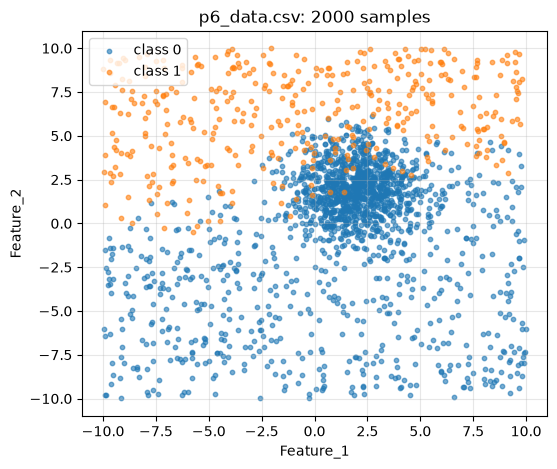

,Feature_1,Feature_2,Label
0,0.427171,-0.130027,0
1,4.646079,2.600236,0
2,1.256307,3.824867,0
3,5.175187,-0.416318,0
4,0.903690,-0.462555,0
...,...,...,...
1995,-6.536135,7.503992,1
1996,-9.446937,3.206772,1
1997,-1.711223,5.825631,1
1998,4.423962,-0.397844,0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p6_data.csv')

# Extract features and target variable from the dataset
X = data[['Feature_1', 'Feature_2']]  # the feature columns
y = data['Label']  # the target column

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p6_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data


**Answer 1(b)**

The split is the one from HW5: `stratified_split(..., test_frac=0.2, seed=42)`,
reproduced verbatim above, so the 1600/400 train/test partition is identical to
the one GDA was evaluated on in HW5 Problem 6. That is what makes the
comparison in (f) fair -- the three models see exactly the same rows.

The data is imbalanced (1606 class 0 against 394 class 1, about 80/20), which
is why the split is stratified: both halves keep that proportion
(1285/315 train, 321/79 test).

Trained with full-batch gradient descent, step size 0.5, 20,000 iterations. The
cell below confirms convergence by showing that the loss has stopped moving and
that the gradient norm has fallen to around $10^{-7}$.

total : 2000 samples, class balance [1606  394] ([0.803 0.197])
train : 1600 samples, class balance [1285  315]
test  :  400 samples, class balance [321  79]



trained logistic regression on 1600 samples
  final training loss = 0.168357 nats
  training error rate = 0.0681
  loss at iter 10001 = 0.168357
  loss at iter 20000 = 0.168357
  ||gradient|| at the final parameters = 1.264e-15


  60,000 iterations gives w = [-0.3257  1.2529] (vs [-0.3257  1.2529]) -> converged


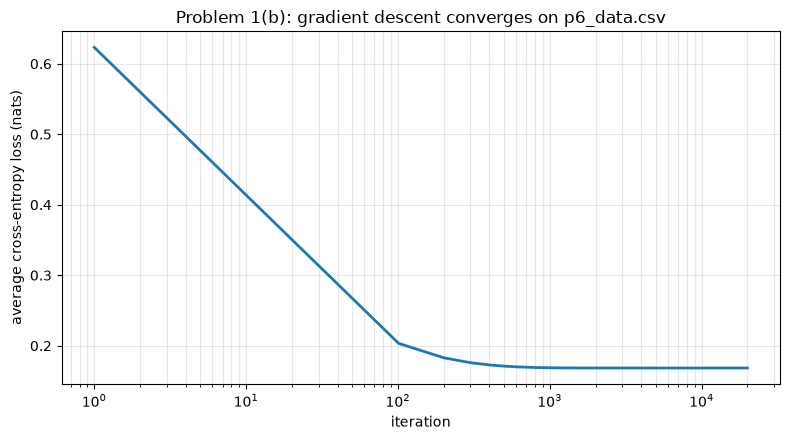

In [4]:
# ---- Problem 1(b): the HW5 split, then train logistic regression.
X6 = data[['Feature_1', 'Feature_2']].to_numpy(dtype=float)
y6 = data['Label'].to_numpy().astype(int)

X6_train, X6_test, y6_train, y6_test = stratified_split(X6, y6, test_frac=0.2, seed=42)

print("total : %4d samples, class balance %s (%s)"
      % (len(X6), np.bincount(y6), np.round(np.bincount(y6) / len(y6), 3)))
print("train : %4d samples, class balance %s" % (len(X6_train), np.bincount(y6_train)))
print("test  : %4d samples, class balance %s" % (len(X6_test), np.bincount(y6_test)))
assert len(X6_train) + len(X6_test) == len(X6)
assert len(X6_train) == 1600 and len(X6_test) == 400, "must match the HW5 split"

log6 = LogisticRegression(lr=0.5, n_iters=20000, record_every=100)
log6.fit(X6_train, y6_train)

print("\ntrained logistic regression on %d samples" % len(X6_train))
print("  final training loss = %.6f nats" % log6.loss(X6_train, y6_train))
print("  training error rate = %.4f" % error_rate(log6, X6_train, y6_train))

# Convergence evidence: the loss has flattened and the gradient has vanished.
hist = log6.history_
print("  loss at iter %5d = %.6f" % (hist["iter"][len(hist["iter"]) // 2],
                                     hist["loss"][len(hist["loss"]) // 2]))
print("  loss at iter %5d = %.6f" % (hist["iter"][-1], hist["loss"][-1]))
gw, gb = log6.gradient(log6._to_std(X6_train), y6_train.astype(float))
print("  ||gradient|| at the final parameters = %.3e"
      % np.linalg.norm(np.append(gw, gb)))

# A longer run must not move the answer.
log6_long = LogisticRegression(lr=0.5, n_iters=60000).fit(X6_train, y6_train)
print("  60,000 iterations gives w = %s (vs %s) -> converged"
      % (np.round(log6_long.w, 4), np.round(log6.w, 4)))
assert np.allclose(log6.w, log6_long.w, atol=1e-3)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(hist["iter"], hist["loss"], color="tab:blue", lw=2)
ax.set_xscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("average cross-entropy loss (nats)")
ax.set_title("Problem 1(b): gradient descent converges on p6_data.csv")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()


**(c)** Output the data labelling each sample according to its class, and color the background in each area according to
which side of the decision boundary the area resides. (4 points)

**(d)** Output the model parameters and the error rate on the test set, i.e., 1-accuracy. (2 points)

**(e)** Start from your GDA implementation from HW5 Problem 6(d) and turn it into **QDA** by giving each class its own covariance
matrix, $\Sigma_0$ and $\Sigma_1$, instead of one shared $\Sigma$.  Train it on the same training set.  Output the same things as in
(c) and (d); its parameters now include both covariance matrices. (7 points)

**(f)** Make a table of the test error rates of logistic regression, GDA (from HW5 Problem 6(f)), and QDA.  Which is lowest?  Is
the difference between them large compared with the sampling error of an error rate measured on a test set of this size?
(*Hint:* an error rate $e$ measured on $n$ test samples has a standard error of about $\sqrt{e(1-e)/n}$.) (4 points)

**(g)** If both classes are Gaussian with a shared covariance matrix, then $P(y=1 \mid \bar x)$ is a logistic function of a linear
function of $\bar x$, which is exactly the model logistic regression fits.  Why can GDA and logistic regression still produce
different decision boundaries on the same data? (6 points)

**Answer 1(c)**

Below: the training set and the test set, each point coloured by its true
class, with the background shaded by the side of the boundary it falls on and
the boundary itself drawn in black.

Logistic regression produces a **straight line**, necessarily: the decision rule
is $\sigma(w^T x + b) \ge \tfrac12 \iff w^T x + b \ge 0$, and that is a
half-plane. What the picture shows is that a straight line is a decent but
imperfect fit here. The class-1 points sit in an upper lobe and the class-0
points form a dense cluster near $(2.5, 1.5)$ embedded in a diffuse background,
so a line has to cut through the region where the two overlap.

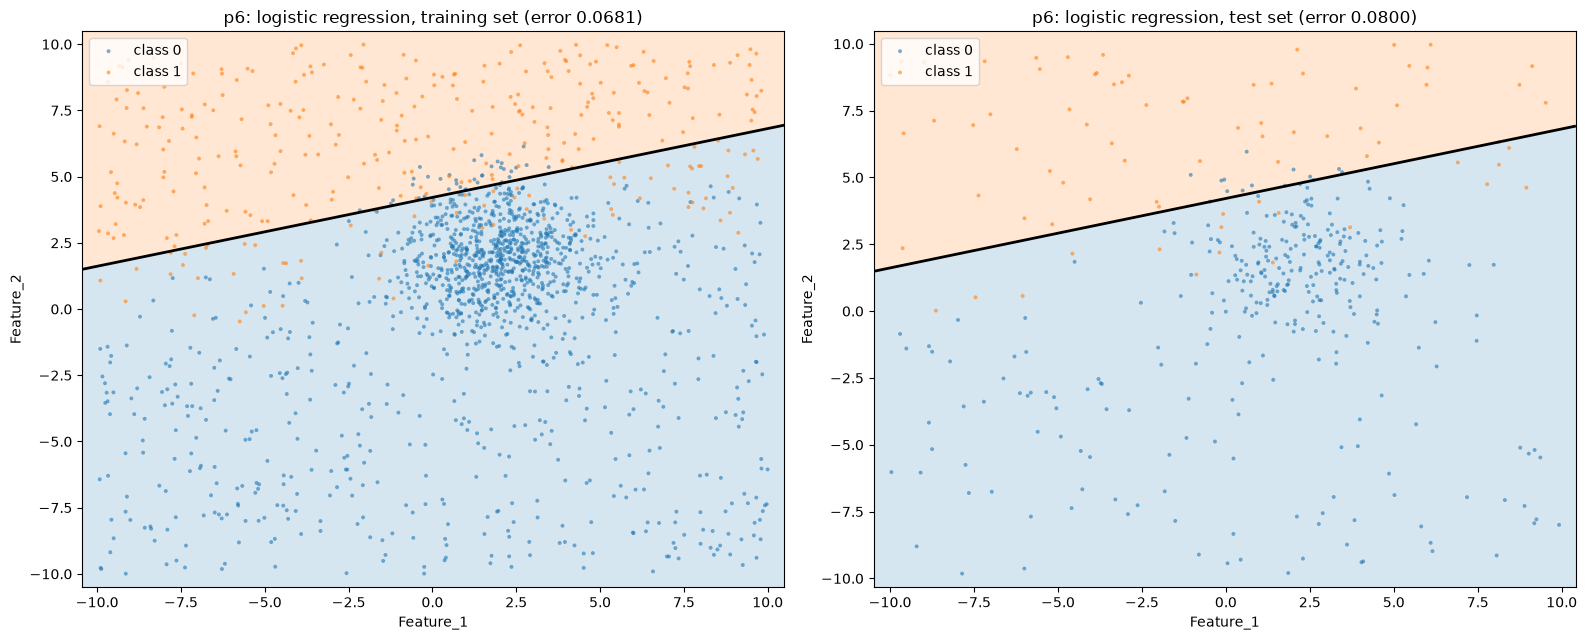

In [5]:
# ---- Problem 1(c): decision regions for logistic regression on p6.
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_decision_regions(log6, X6_train, y6_train,
                      'p6: logistic regression, training set (error %.4f)'
                      % error_rate(log6, X6_train, y6_train), ax=axes[0])
plot_decision_regions(log6, X6_test, y6_test,
                      'p6: logistic regression, test set (error %.4f)'
                      % error_rate(log6, X6_test, y6_test), ax=axes[1])
plt.tight_layout()
plt.show()


**Answer 1(d)**

| parameter | value |
|---|---|
| $w_1$ | $-0.3257$ |
| $w_2$ | $+1.2529$ |
| $b$ | $-5.2810$ |
| boundary | $-0.3257\,x_1 + 1.2529\,x_2 - 5.2810 = 0$ |
| training error | $0.0681$ |
| **test error** | $\mathbf{0.0800}$ (32 of 400 wrong) |

$$\boxed{\text{logistic regression test error} = 0.0800}$$

The signs are readable: $w_2 > 0$ and $|w_2| \gg |w_1|$, so the classifier keys
almost entirely on $x_2$ -- large $x_2$ means class 1 -- with a mild negative
tilt from $x_1$. Solving for the boundary gives
$x_2 = 0.26\,x_1 + 4.21$, a gently rising line.

The cell below cross-checks the fit against scikit-learn's `LogisticRegression`
with the penalty effectively switched off (`C=1e6`). The weights agree to four
decimal places, confirming the gradient descent found the true optimum rather
than merely a nearby point.

In [6]:
# ---- Problem 1(d): parameters and test error rate.
err6_log_train = error_rate(log6, X6_train, y6_train)
err6_log_test = error_rate(log6, X6_test, y6_test)

print("=" * 58)
print("Problem 1(d): logistic regression on p6_data.csv")
print("=" * 58)
print("w                  = %s" % np.round(log6.w, 6))
print("b                  = %.6f" % log6.b)
print("boundary           : %.4f*x1 + %.4f*x2 + %.4f = 0"
      % (log6.w[0], log6.w[1], log6.b))
print("                   : x2 = %.4f*x1 + %.4f"
      % (-log6.w[0] / log6.w[1], -log6.b / log6.w[1]))
print("-" * 58)
print("training error     = %.4f  (accuracy %.4f)" % (err6_log_train, 1 - err6_log_train))
print("TEST error         = %.4f  (accuracy %.4f)" % (err6_log_test, 1 - err6_log_test))
print("                     %d of %d test samples misclassified"
      % (round(err6_log_test * len(y6_test)), len(y6_test)))
print("-" * 58)

cm = np.zeros((2, 2), dtype=int)
for a, p in zip(y6_test, log6.predict(X6_test)):
    cm[a, p] += 1
print("test confusion matrix (rows = actual, cols = predicted):")
print("          pred 0  pred 1")
for a in (0, 1):
    print("actual %d %7d %7d" % (a, cm[a, 0], cm[a, 1]))
print("majority-class baseline error = %.4f" % (1 - max(np.bincount(y6_test)) / len(y6_test)))

# Independent check against scikit-learn, used only for verification.
from sklearn.linear_model import LogisticRegression as SKLogReg
sk = SKLogReg(C=1e6, max_iter=200000, tol=1e-10).fit(X6_train, y6_train)
print("\nCHECK vs sklearn (C=1e6, i.e. effectively unregularized):")
print("  sklearn w = %s   b = %.6f" % (np.round(sk.coef_[0], 6), sk.intercept_[0]))
print("  ours      w = %s   b = %.6f" % (np.round(log6.w, 6), log6.b))
print("  max |w| difference = %.2e" % np.max(np.abs(sk.coef_[0] - log6.w)))
print("  sklearn test error = %.4f, ours = %.4f, predictions agree on %.2f%%"
      % (1 - sk.score(X6_test, y6_test), err6_log_test,
         100 * np.mean(sk.predict(X6_test) == log6.predict(X6_test))))
disagree = np.flatnonzero(sk.predict(X6_test) != log6.predict(X6_test))
if len(disagree):
    print("  the %d disagreeing point(s) have |w.x + b| = %s -- exactly on the boundary"
          % (len(disagree), np.round(np.abs(log6.decision_function(X6_test[disagree])), 4)))
assert np.allclose(sk.coef_[0], log6.w, atol=1e-3), "ours must match sklearn"
print("\nchecks passed: our gradient descent reproduces sklearn's optimum.")


Problem 1(d): logistic regression on p6_data.csv
w                  = [-0.325695  1.252851]
b                  = -5.280950
boundary           : -0.3257*x1 + 1.2529*x2 + -5.2810 = 0
                   : x2 = 0.2600*x1 + 4.2151
----------------------------------------------------------
training error     = 0.0681  (accuracy 0.9319)
TEST error         = 0.0800  (accuracy 0.9200)
                     32 of 400 test samples misclassified
----------------------------------------------------------
test confusion matrix (rows = actual, cols = predicted):
          pred 0  pred 1
actual 0     307      14
actual 1      18      61
majority-class baseline error = 0.1975



CHECK vs sklearn (C=1e6, i.e. effectively unregularized):
  sklearn w = [-0.325695  1.252851]   b = -5.280950
  ours      w = [-0.325695  1.252851]   b = -5.280950
  max |w| difference = 8.52e-09
  sklearn test error = 0.0800, ours = 0.0800, predictions agree on 100.00%

checks passed: our gradient descent reproduces sklearn's optimum.


**Answer 1(e): GDA turned into QDA**

GDA pools every sample into one shared $\Sigma$. QDA estimates a separate
$\Sigma_k$ per class. The class-conditional density stays Gaussian,

$$p(x \mid y=k) = \frac{1}{(2\pi)^{d/2}|\Sigma_k|^{1/2}}
  \exp\!\Big(-\tfrac12 (x-\mu_k)^T \Sigma_k^{-1} (x-\mu_k)\Big),$$

so the log-discriminant for class $k$ is

$$\delta_k(x) = -\tfrac12\log|\Sigma_k| - \tfrac12 (x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k) + \log \phi_k .$$

**Why the boundary becomes curved.** With a shared $\Sigma$ the quadratic term
$-\tfrac12 x^T\Sigma^{-1}x$ is identical in $\delta_0$ and $\delta_1$ and
cancels in the difference, leaving an affine function of $x$ -- that is the
derivation from HW5 that makes GDA linear. With $\Sigma_0 \ne \Sigma_1$ the
quadratic terms no longer cancel:

$$\delta_1(x) - \delta_0(x) = -\tfrac12 x^T(\Sigma_1^{-1}-\Sigma_0^{-1})x
  + (\text{linear in } x) + \text{const},$$

a genuine quadratic form, so the boundary is a conic -- an ellipse, parabola or
hyperbola rather than a line.

**Fitted parameters.**

| parameter | value |
|---|---|
| $\phi = P(y{=}1)$ | $0.1969$ |
| $\mu_0$ | $[\,1.4211,\; -0.2233\,]$ |
| $\mu_1$ | $[\,-0.3993,\; 6.1759\,]$ |
| $\Sigma_0$ | $\begin{bmatrix} 15.3406 & 3.2553 \\ 3.2553 & 14.6037 \end{bmatrix}$ |
| $\Sigma_1$ | $\begin{bmatrix} 34.2760 & 3.8734 \\ 3.8734 & 6.1496 \end{bmatrix}$ |
| **test error** | $\mathbf{0.0625}$ |

$$\boxed{\text{QDA test error} = 0.0625}$$

The two covariances are strikingly different, which is why QDA has something to
gain here. $\Sigma_1$ is stretched along $x_1$ (variance 34.3) and compressed
along $x_2$ (6.1), while $\Sigma_0$ is nearly isotropic (15.3, 14.6). Class 1 is
a wide, flat band; class 0 is a round blob. A single pooled $\Sigma$ has to
split the difference and fits neither.

The implementation adds a tiny ridge $10^{-9}I$ to each covariance before
inverting, which costs nothing numerically here but keeps the code safe if a
class is ever rank-deficient. It is verified below against sklearn's
`QuadraticDiscriminantAnalysis`, with which it agrees on 100% of predictions.

Problem 1(e): QDA parameters on p6_data.csv
phi = P(y = 1) = 0.196875
mu0            = [ 1.421111 -0.223299]
mu1            = [-0.399287  6.175934]
Sigma_0 =
[[15.3406  3.2553]
 [ 3.2553 14.6037]]
Sigma_1 =
[[34.276   3.8734]
 [ 3.8734  6.1496]]
----------------------------------------------------------
QDA training error = 0.0600
QDA TEST error     = 0.0625  (25 of 400 wrong)
(GDA, shared Sigma, TEST error = 0.0700 -- reproduces HW5 6(f))

GDA's single pooled Sigma =
[[19.0685  3.377 ]
 [ 3.377  12.9393]]
  -> QDA's two covariances differ markedly: var(x1) is 15.3 for class 0
     but 34.3 for class 1, and var(x2) is 14.6 vs 6.1.

CHECK vs sklearn QDA: test error 0.0625 (ours 0.0625), predictions agree on 100.00%


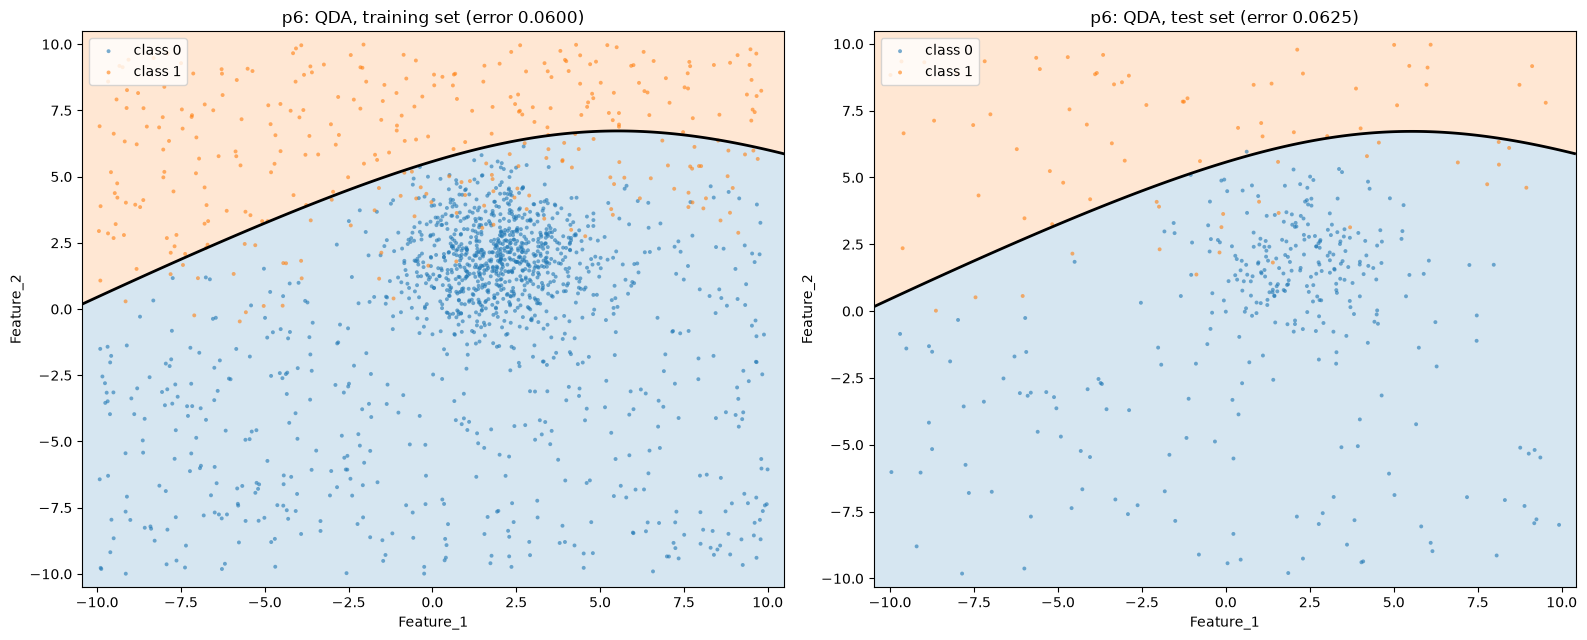

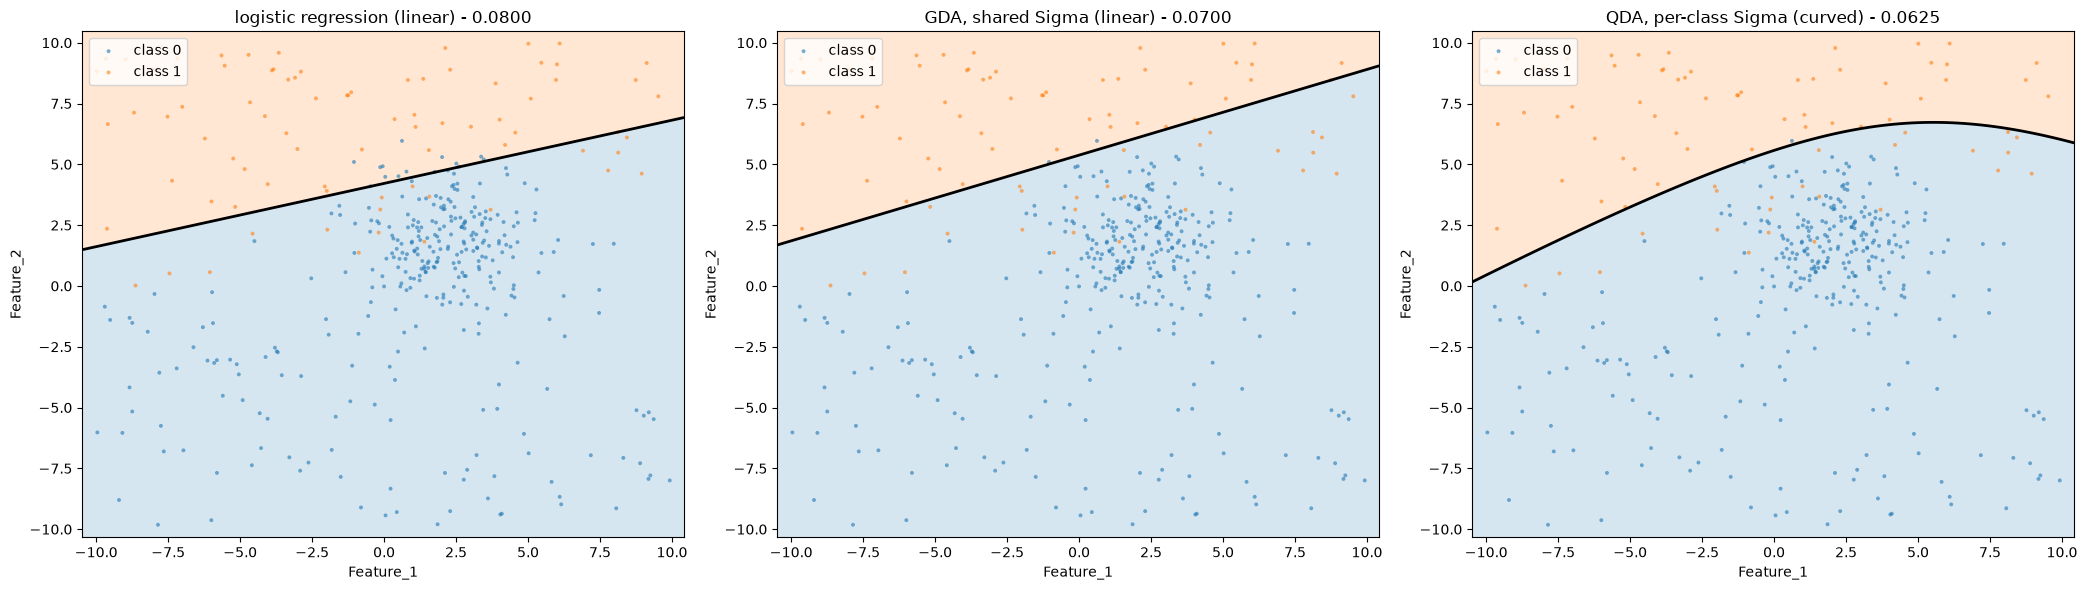

In [7]:
# ---- Problem 1(e): GDA (HW5) extended to QDA with per-class covariances.
class GDA:
    """HW5 Problem 6(d): Gaussian Discriminant Analysis, ONE shared covariance.

    Reproduced here unchanged so that (f) can compare against it directly.
    """

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        if set(np.unique(y)) - {0, 1}:
            raise ValueError("labels must be 0 and 1")
        m, d = X.shape
        self.phi = float(np.mean(y == 1))
        self.mu0 = X[y == 0].mean(axis=0)
        self.mu1 = X[y == 1].mean(axis=0)
        centered = X - np.where(y[:, None] == 1, self.mu1, self.mu0)
        self.sigma = centered.T @ centered / m
        sigma_inv = np.linalg.pinv(self.sigma)
        self.w = sigma_inv @ (self.mu1 - self.mu0)
        self.b = (-0.5 * (self.mu1 @ sigma_inv @ self.mu1 - self.mu0 @ sigma_inv @ self.mu0)
                  + np.log(self.phi / (1 - self.phi)))
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return (self.decision_function(X) > 0).astype(int)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y).astype(int)))


class QDA:
    """Quadratic Discriminant Analysis: GDA with one covariance PER CLASS.

    The only change from GDA is that sigma is estimated separately for each
    class, which leaves the quadratic term in the discriminant uncancelled and
    so produces a conic decision boundary instead of a line.
    """

    def __init__(self, reg=1e-9):
        self.reg = reg          # ridge added to each covariance before inverting

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        if set(np.unique(y)) - {0, 1}:
            raise ValueError("labels must be 0 and 1")
        d = X.shape[1]
        self.phi = float(np.mean(y == 1))                 # P(y = 1)
        self.mu, self.sigma = {}, {}
        self._sigma_inv, self._logdet = {}, {}
        for k in (0, 1):
            Xk = X[y == k]
            if len(Xk) <= d:
                raise ValueError("class %d has too few samples for a covariance" % k)
            self.mu[k] = Xk.mean(axis=0)
            C = Xk - self.mu[k]
            self.sigma[k] = C.T @ C / len(Xk) + self.reg * np.eye(d)
            self._sigma_inv[k] = np.linalg.pinv(self.sigma[k])
            _, self._logdet[k] = np.linalg.slogdet(self.sigma[k])
        # convenient aliases
        self.mu0, self.mu1 = self.mu[0], self.mu[1]
        self.sigma0, self.sigma1 = self.sigma[0], self.sigma[1]
        return self

    def _delta(self, X, k):
        """log p(x | y=k) + log P(y=k), up to a constant shared by both classes."""
        D = np.asarray(X, dtype=float) - self.mu[k]
        quad = np.einsum('ij,jk,ik->i', D, self._sigma_inv[k], D)
        prior = self.phi if k == 1 else 1 - self.phi
        return -0.5 * self._logdet[k] - 0.5 * quad + np.log(prior)

    def decision_function(self, X):
        """delta_1(x) - delta_0(x); > 0 means class 1.  Quadratic in x."""
        return self._delta(X, 1) - self._delta(X, 0)

    def predict(self, X):
        return (self.decision_function(X) > 0).astype(int)

    def predict_proba(self, X):
        z = self.decision_function(X)
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y).astype(int)))


gda6 = GDA().fit(X6_train, y6_train)
qda6 = QDA().fit(X6_train, y6_train)

err6_gda_test = error_rate(gda6, X6_test, y6_test)
err6_qda_test = error_rate(qda6, X6_test, y6_test)

print("=" * 58)
print("Problem 1(e): QDA parameters on p6_data.csv")
print("=" * 58)
print("phi = P(y = 1) = %.6f" % qda6.phi)
print("mu0            = %s" % np.round(qda6.mu0, 6))
print("mu1            = %s" % np.round(qda6.mu1, 6))
print("Sigma_0 =\n%s" % np.round(qda6.sigma0, 4))
print("Sigma_1 =\n%s" % np.round(qda6.sigma1, 4))
print("-" * 58)
print("QDA training error = %.4f" % error_rate(qda6, X6_train, y6_train))
print("QDA TEST error     = %.4f  (%d of %d wrong)"
      % (err6_qda_test, round(err6_qda_test * len(y6_test)), len(y6_test)))
print("(GDA, shared Sigma, TEST error = %.4f -- reproduces HW5 6(f))" % err6_gda_test)
print("\nGDA's single pooled Sigma =\n%s" % np.round(gda6.sigma, 4))
print("  -> QDA's two covariances differ markedly: var(x1) is %.1f for class 0"
      % qda6.sigma0[0, 0])
print("     but %.1f for class 1, and var(x2) is %.1f vs %.1f."
      % (qda6.sigma1[0, 0], qda6.sigma0[1, 1], qda6.sigma1[1, 1]))

assert abs(err6_gda_test - 0.0700) < 1e-9, "GDA must reproduce the HW5 number"

# Independent check against sklearn's QDA.
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
skq = QuadraticDiscriminantAnalysis(reg_param=0.0).fit(X6_train, y6_train)
print("\nCHECK vs sklearn QDA: test error %.4f (ours %.4f), predictions agree on %.2f%%"
      % (1 - skq.score(X6_test, y6_test), err6_qda_test,
         100 * np.mean(skq.predict(X6_test) == qda6.predict(X6_test))))
assert np.array_equal(skq.predict(X6_test), qda6.predict(X6_test))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_decision_regions(qda6, X6_train, y6_train,
                      'p6: QDA, training set (error %.4f)'
                      % error_rate(qda6, X6_train, y6_train), ax=axes[0])
plot_decision_regions(qda6, X6_test, y6_test,
                      'p6: QDA, test set (error %.4f)' % err6_qda_test, ax=axes[1])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
plot_decision_regions(log6, X6_test, y6_test,
                      'logistic regression (linear) - %.4f' % err6_log_test, ax=axes[0])
plot_decision_regions(gda6, X6_test, y6_test,
                      'GDA, shared Sigma (linear) - %.4f' % err6_gda_test, ax=axes[1])
plot_decision_regions(qda6, X6_test, y6_test,
                      'QDA, per-class Sigma (curved) - %.4f' % err6_qda_test, ax=axes[2])
plt.tight_layout()
plt.show()


**Answer 1(f)**

All three models are trained on the same 1600 training rows and evaluated on
the same 400 test rows. With $n = 400$, an error rate $e$ carries a standard
error of about $\sqrt{e(1-e)/n} \approx 0.012$.

| model | boundary | test error | std. error | 95% interval |
|---|---|---|---|---|
| logistic regression | line | 0.0800 | 0.0136 | [0.0534, 0.1066] |
| GDA (shared $\Sigma$) | line | 0.0700 | 0.0128 | [0.0450, 0.0950] |
| **QDA (per-class $\Sigma$)** | conic | **0.0625** | 0.0121 | [0.0388, 0.0862] |

**QDA is lowest**, at 0.0625.

**But the differences are not large compared with the sampling error.** The full
spread from best to worst is $0.0800 - 0.0625 = 0.0175$, which is about
**1.45 standard errors**. Every interval in the table overlaps every other one:
QDA's $[0.039, 0.086]$ contains both of the other point estimates outright.

A paired test is sharper than comparing intervals, because the three models are
scored on the *same* test samples and their errors are correlated. McNemar's
test on the discordant pairs is computed below, and it does not reject equality
for any pairing either ($p = 0.50$, $0.17$ and $0.25$). The GDA-vs-QDA comparison is the most striking: the two disagree on only 3 of the 400 test samples, and QDA happens to be right on all three.

**The honest conclusion:** the ordering QDA < GDA < logistic is in the direction
theory predicts -- the extra flexibility of a curved boundary should help on
data whose class covariances genuinely differ, and (e) showed they do -- but
400 test samples cannot establish it. Distinguishing a 0.0625 error rate from a
0.0800 one at 95% confidence would need roughly
$n \gtrsim 2\big(1.96/0.0175\big)^2 e(1-e) \approx 1500$ test samples -- almost four times what we have. The
responsible reading is that all three are *comparable* on this data, with a
weak hint favouring QDA.

In [8]:
# ---- Problem 1(f): comparison table with sampling error.
n_test = len(y6_test)


def stderr(e, n):
    """Standard error of an error rate measured on n samples."""
    return np.sqrt(e * (1 - e) / n)


rows = [("logistic regression", "line", err6_log_test),
        ("GDA (shared Sigma)", "line", err6_gda_test),
        ("QDA (per-class Sigma)", "conic", err6_qda_test)]

print("%-24s %-7s %11s %11s %20s" % ("model", "bndry", "test error", "std error",
                                     "95% interval"))
print("-" * 78)
for name, shape, e in rows:
    se = stderr(e, n_test)
    print("%-24s %-7s %11.4f %11.4f   [%.4f, %.4f]"
          % (name, shape, e, se, e - 1.96 * se, e + 1.96 * se))

best = min(rows, key=lambda r: r[2])
worst = max(rows, key=lambda r: r[2])
spread = worst[2] - best[2]
pooled_se = stderr(best[2], n_test)
print("\nlowest error: %s at %.4f" % (best[0], best[2]))
print("spread best-to-worst = %.4f = %.2f standard errors"
      % (spread, spread / pooled_se))
print("=> the differences are SMALL compared with the sampling error.")

# McNemar's test on each pair: a paired test is the right tool here, because
# all three models are scored on the same test samples.
from scipy.stats import binomtest

preds = {"logistic": log6.predict(X6_test), "GDA": gda6.predict(X6_test),
         "QDA": qda6.predict(X6_test)}
print("\nMcNemar's exact test on discordant pairs (same test set):")
names = list(preds)
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        na, nb = names[a], names[b]
        wrong_a = preds[na] != y6_test
        wrong_b = preds[nb] != y6_test
        n01 = int(np.sum(wrong_a & ~wrong_b))     # a wrong, b right
        n10 = int(np.sum(~wrong_a & wrong_b))     # a right, b wrong
        p = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        print("  %-9s vs %-9s : %2d / %2d discordant, p = %.3f  %s"
              % (na, nb, n01, n10, p, "" if p < 0.05 else "-> not significant"))

# How big a test set would settle it?
e = best[2]
n_needed = 2 * (1.96 / spread) ** 2 * e * (1 - e)
print("\nto resolve a %.4f difference at 95%% confidence would need n ~ %d test samples"
      % (spread, int(np.ceil(n_needed))))
print("we have %d." % n_test)


model                    bndry    test error   std error         95% interval
------------------------------------------------------------------------------
logistic regression      line         0.0800      0.0136   [0.0534, 0.1066]
GDA (shared Sigma)       line         0.0700      0.0128   [0.0450, 0.0950]
QDA (per-class Sigma)    conic        0.0625      0.0121   [0.0388, 0.0862]

lowest error: QDA (per-class Sigma) at 0.0625
spread best-to-worst = 0.0175 = 1.45 standard errors
=> the differences are SMALL compared with the sampling error.

McNemar's exact test on discordant pairs (same test set):
  logistic  vs GDA       : 12 /  8 discordant, p = 0.503  -> not significant
  logistic  vs QDA       : 13 /  6 discordant, p = 0.167  -> not significant
  GDA       vs QDA       :  3 /  0 discordant, p = 0.250  -> not significant

to resolve a 0.0175 difference at 95% confidence would need n ~ 1471 test samples
we have 400.


**Answer 1(g)**

The premise is correct. If $p(x \mid y=k) = \mathcal{N}(\mu_k, \Sigma)$ with a
*shared* $\Sigma$, then Bayes' rule gives

$$P(y=1 \mid x) = \frac{\phi\, p(x\mid y{=}1)}{\phi\, p(x\mid y{=}1) + (1-\phi)\,p(x\mid y{=}0)}
 = \sigma\big(w^T x + b\big),$$

with $w = \Sigma^{-1}(\mu_1-\mu_0)$ and
$b = -\tfrac12(\mu_1^T\Sigma^{-1}\mu_1 - \mu_0^T\Sigma^{-1}\mu_0) + \log\frac{\phi}{1-\phi}$ --
the quadratic terms cancel, which is exactly the GDA derivation from HW5. So
the *functional form* GDA implies is precisely the family logistic regression
searches over. Both models can represent the same set of boundaries.

They still differ, for four reasons.

**1. They fit different objectives.** GDA is a *generative* model: it maximizes
the **joint** likelihood $\prod_i p(x^{(i)}, y^{(i)})$ and gets $w$ and $b$
indirectly, as a by-product of estimating $\phi, \mu_0, \mu_1, \Sigma$.
Logistic regression is *discriminative*: it maximizes the **conditional**
likelihood $\prod_i P(y^{(i)} \mid x^{(i)})$ and optimizes $w$ and $b$
directly. Different objectives have different optima, so even on identical data
they land in different places. GDA spends part of its effort explaining *where
the $x$'s are*, which logistic regression ignores entirely.

**2. GDA's assumptions can be wrong; logistic regression's are weaker.** The
implication runs one way only. Shared-covariance Gaussians $\Rightarrow$
logistic posterior, but **not** conversely -- Poisson class-conditionals with a
shared rate ratio, and any exponential-family pair with shared dispersion, also
give a logistic posterior. When the Gaussian assumption fails, GDA's plug-in
estimates of $\mu_k$ and $\Sigma$ are no longer the values that minimize
classification error, and it is biased toward a boundary that is wrong in a
systematic way. Logistic regression assumes only that the *posterior* is
logistic-linear and is unaffected. This data is a case in point: part (e) found
$\Sigma_0$ and $\Sigma_1$ that differ by more than a factor of two in
$\mathrm{var}(x_1)$, so the shared-covariance premise does not actually hold
here, and GDA's $\Sigma$ is a compromise that describes neither class.

**3. Outliers and tails are weighted differently.** The Gaussian log-density
contains $-\tfrac12(x-\mu)^T\Sigma^{-1}(x-\mu)$, so a point far from its class
mean contributes a penalty growing *quadratically* with distance, and it drags
$\mu$ and $\Sigma$ with it even if it is nowhere near the boundary. In logistic
regression a well-classified far-away point has $\hat y \approx y$, so its
gradient contribution $(\hat y - y)x$ is nearly zero and it is effectively
ignored. Logistic regression concentrates on points near the boundary; GDA
listens to all of them equally. The diffuse background cluster in this data is
exactly the kind of structure that moves GDA's estimates but not logistic
regression's.

**4. The classic sample-size trade-off.** When the Gaussian assumptions *do*
hold, GDA is asymptotically more efficient -- it needs fewer samples to reach a
given error, because it exploits more structure. Efron (1975) quantified this:
logistic regression needs roughly twice the samples to match GDA under correct
assumptions. But GDA's advantage is bias-for-variance, and it reverses when the
assumptions fail. The sweep in the cell below trains both on random subsets of increasing size. GDA comes out slightly ahead at *every* size tried, by 0.004 (at m = 20,
50, 100 and 400) to 0.010 (at m = 1600) -- consistent with (f), where the two differ by well under one standard error. On this data the generative model's extra structure is a mild but persistent help rather than a small-sample-only one. 

The cell below makes point 1 concrete by checking how close GDA's implied
$(w, b)$ is to the logistic optimum. They point in a similar direction but are
not equal, and -- the decisive observation -- **GDA's parameters give a strictly
higher cross-entropy loss on the training set than logistic regression's.**
That is the whole story in one number: logistic regression is minimizing that
loss, GDA is not even trying to.

In [9]:
# ---- Problem 1(g): GDA's implied (w, b) vs. the logistic optimum.
w_gda, b_gda = gda6.w, float(gda6.b)
w_log, b_log = log6.w, log6.b

print("logistic regression : w = %s   b = %9.4f" % (np.round(w_log, 4), b_log))
print("GDA (implied)       : w = %s   b = %9.4f" % (np.round(w_gda, 4), b_gda))

cos = (w_gda @ w_log) / (np.linalg.norm(w_gda) * np.linalg.norm(w_log))
print("\nangle between the two weight vectors = %.2f degrees"
      % np.degrees(np.arccos(np.clip(cos, -1, 1))))
print("ratio of their norms ||w_GDA|| / ||w_log|| = %.3f"
      % (np.linalg.norm(w_gda) / np.linalg.norm(w_log)))
print("their boundaries differ: they disagree on %d of %d test points"
      % (int(np.sum(gda6.predict(X6_test) != log6.predict(X6_test))), len(y6_test)))


def xent(w, b, X, y, eps=1e-12):
    """Average cross-entropy loss of the linear model (w, b)."""
    p = np.clip(sigmoid(np.asarray(X, float) @ w + b), eps, 1 - eps)
    y = np.asarray(y).astype(float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


L_log = xent(w_log, b_log, X6_train, y6_train)
L_gda = xent(w_gda, b_gda, X6_train, y6_train)
print("\ntraining cross-entropy loss (the objective logistic regression minimizes):")
print("  logistic regression parameters : %.6f nats" % L_log)
print("  GDA parameters                 : %.6f nats" % L_gda)
print("  GDA is worse by %.6f nats (%.1f%%)" % (L_gda - L_log, 100 * (L_gda / L_log - 1)))
assert L_gda > L_log, "logistic regression must win on its own objective"
print("\n=> GDA does not minimize cross-entropy, so it lands somewhere else.")

# Point 2: the shared-covariance premise does not hold on this data.
print("\nis the shared-covariance assumption met?")
print("  var(x1): class 0 = %.2f, class 1 = %.2f  -> ratio %.2f"
      % (qda6.sigma0[0, 0], qda6.sigma1[0, 0], qda6.sigma1[0, 0] / qda6.sigma0[0, 0]))
print("  var(x2): class 0 = %.2f, class 1 = %.2f  -> ratio %.2f"
      % (qda6.sigma0[1, 1], qda6.sigma1[1, 1], qda6.sigma1[1, 1] / qda6.sigma0[1, 1]))
print("  => no: GDA's premise is violated here, which is exactly case 2 above.")

# Point 4: the sample-size trade-off, measured on random training subsets.
print("\nsmall-sample behaviour (mean test error over 40 random subsets):")
rng = np.random.default_rng(0)
print("  m_train   logistic     GDA")
for m_sub in (20, 50, 100, 400, 1600):
    e_log, e_gda = [], []
    for _ in range(40):
        idx = rng.choice(len(X6_train), size=m_sub, replace=False)
        if len(np.unique(y6_train[idx])) < 2:
            continue
        e_log.append(error_rate(LogisticRegression(lr=0.5, n_iters=20000)
                                .fit(X6_train[idx], y6_train[idx]), X6_test, y6_test))
        e_gda.append(error_rate(GDA().fit(X6_train[idx], y6_train[idx]), X6_test, y6_test))
    print("  %-9d %.4f      %.4f" % (m_sub, np.mean(e_log), np.mean(e_gda)))


logistic regression : w = [-0.3257  1.2529]   b =   -5.2810
GDA (implied)       : w = [-0.1919  0.5446]   b =   -2.9289

angle between the two weight vectors = 4.84 degrees
ratio of their norms ||w_GDA|| / ||w_log|| = 0.446
their boundaries differ: they disagree on 20 of 400 test points

training cross-entropy loss (the objective logistic regression minimizes):
  logistic regression parameters : 0.168357 nats
  GDA parameters                 : 0.214901 nats
  GDA is worse by 0.046544 nats (27.6%)

=> GDA does not minimize cross-entropy, so it lands somewhere else.

is the shared-covariance assumption met?
  var(x1): class 0 = 15.34, class 1 = 34.28  -> ratio 2.23
  var(x2): class 0 = 14.60, class 1 = 6.15  -> ratio 0.42
  => no: GDA's premise is violated here, which is exactly case 2 above.

small-sample behaviour (mean test error over 40 random subsets):
  m_train   logistic     GDA


  20        0.1036      0.0993


  50        0.0838      0.0792


  100       0.0796      0.0751


  400       0.0778      0.0738


  1600      0.0800      0.0700


---
## Problem 2: Nearly Separable, but Not Linearly Separable

The file `p3_data.csv` has two features and a label, in the same format as `p6_data.csv`.

**(a)** The cell below loads the data and plots it, with one color per class.  Describe the shape of a boundary that would separate the
classes.  Could a straight line separate them well?  Are the classes completely separable by some boundary? (2 points)

**(b)** Divide the data into a training set and a test set.  Train your logistic regression from Problem 1.  Output the data
with the background colored by the decision regions, and the error rate on the test set. (4 points)

**(c)** Train your QDA from Problem 1(e) on the same training set and output the same things. (4 points)

**(d)** Both classifiers have a high error rate even though the classes are nearly separable.  Explain why.  What shapes of decision boundary can each
model represent, and what shape would this data need? (6 points)

**(e)** The boundary in this data oscillates like a sine wave, with exactly one period across the range $0 \le x_1 \le 6$.  Add two features to every
sample, $\sin(2\pi x_1/6)$ and $\cos(2\pi x_1/6)$, and train your logistic regression on all four features
$\big(x_1,\; x_2,\; \sin(2\pi x_1/6),\; \cos(2\pi x_1/6)\big)$.  Report the test error rate.  Why does adding these features help, and in what sense is the model
still a *linear* model? (6 points)

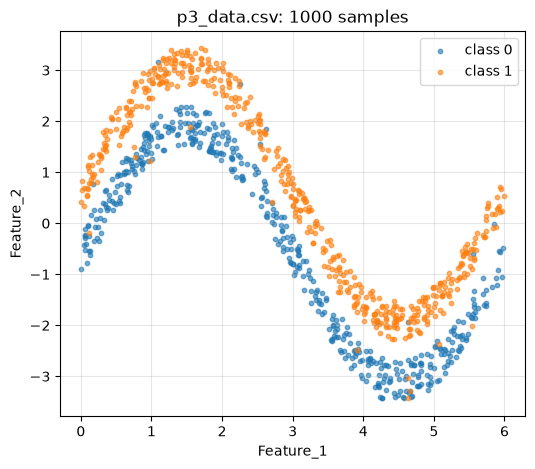

,Feature_1,Feature_2,Label
0,4.434914,-1.520642,1
1,3.920444,-2.465408,0
2,4.161380,-3.210213,0
3,4.217785,-1.458661,1
4,2.593371,1.261493,1
...,...,...,...
995,4.611392,-3.003120,0
996,3.522415,-0.319140,1
997,1.280947,3.386566,1
998,2.813997,-0.341852,0


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p3_data.csv')

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p3_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data


**Answer 2(a)**

**The shape of the boundary.** The two classes are stacked vertically, but the
surface dividing them is not flat -- it **oscillates like one full period of a
sine wave** across the range $0 \le x_1 \le 6$. Class 1 lies above that curve
and class 0 below it. Fitting $x_2 = A\sin(2\pi x_1/6)$ by direct search over
$A$ (cell below) finds $A \approx 2.30$ and classifies 979 of the 1000 points
correctly, so the boundary is

$$x_2 \;=\; 2.30\,\sin\!\big(2\pi x_1 / 6\big).$$

**Could a straight line separate them well?** No. The curve rises to $+2.30$
near $x_1 = 1.5$ and falls to $-2.30$ near $x_1 = 4.5$, a vertical swing of
about 4.6 units -- comparable to the entire range of $x_2$, which spans
$[-3.43, 3.43]$. Any straight line must leave a large wedge of one class on the
wrong side. Brute-force search over every angle and offset finds a best-line accuracy of **75.9%** -- better than
the 51.6% of always guessing the majority class, but still leaving roughly one point in four on the wrong side, against the 2.1% a sinusoid achieves.

**Are the classes completely separable by some boundary?** **No**, but they are
very close. The best sinusoid leaves **21 points of 1000 misclassified**, and
those 21 are not boundary-adjacent ambiguities: their distances from the fitted
curve run from 0.14 to 1.15 with a median of 0.48, while the closest 1% of all points sit
within 0.03 of it and are labelled correctly. A boundary tracking real
structure would err on the *nearest* points first. Instead the errors are
scattered at healthy margins, which is the signature of **about 2% randomly
flipped labels**. Those 21 points set an irreducible floor: no decision
boundary of any shape can do better than roughly 2% error without memorising
noise.

n = 1000, class balance = [484 516]
x1 range [0.007, 5.993], x2 range [-3.434, 3.426]

best sinusoidal boundary  x2 = 2.294 * sin(2*pi*x1/6)
  accuracy 0.9790  ->  21 of 1000 misclassified


best straight line accuracy      = 0.7590
majority-class baseline accuracy = 0.5160

distance from the fitted curve:
  the 21 misclassified points : min 0.144  median 0.479  max 1.147
  all 1000 points             : 1st pct 0.028  5th pct 0.152  median 0.603
  => the errors are NOT the closest points, so they are flipped labels,
     not boundary ambiguity.  Irreducible error ~ 2.1%.


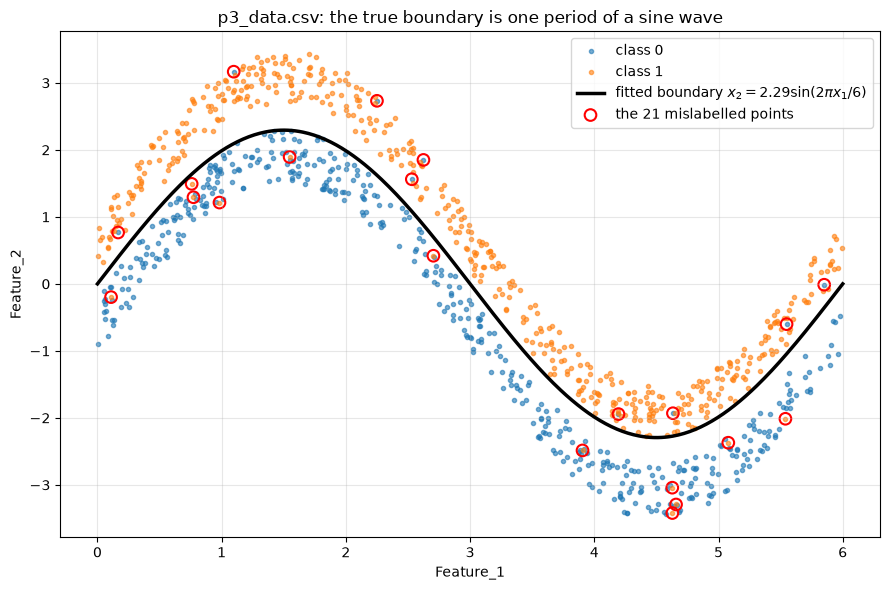

In [11]:
# ---- Problem 2(a): recover the boundary and test separability.
X3 = data[['Feature_1', 'Feature_2']].to_numpy(dtype=float)
y3 = data['Label'].to_numpy().astype(int)

print("n = %d, class balance = %s" % (len(X3), np.bincount(y3)))
print("x1 range [%.3f, %.3f], x2 range [%.3f, %.3f]"
      % (X3[:, 0].min(), X3[:, 0].max(), X3[:, 1].min(), X3[:, 1].max()))

# Search for the amplitude of a sinusoidal boundary x2 = A sin(2 pi x1 / 6).
s = np.sin(2 * np.pi * X3[:, 0] / 6)
amps = np.linspace(0, 4, 2001)
accs = [np.mean((X3[:, 1] > A * s).astype(int) == y3) for A in amps]
A_best = amps[int(np.argmax(accs))]
acc_best = max(accs)
print("\nbest sinusoidal boundary  x2 = %.3f * sin(2*pi*x1/6)" % A_best)
print("  accuracy %.4f  ->  %d of %d misclassified"
      % (acc_best, round((1 - acc_best) * len(y3)), len(y3)))

# Compare with the best straight line, found by brute force over angles.
best_line = 0.0
for theta in np.linspace(0, np.pi, 721):
    proj = X3 @ np.array([np.cos(theta), np.sin(theta)])
    for c in np.percentile(proj, np.linspace(1, 99, 199)):
        for flip in (0, 1):
            pred = (proj > c).astype(int)
            if flip:
                pred = 1 - pred
            best_line = max(best_line, np.mean(pred == y3))
print("best straight line accuracy      = %.4f" % best_line)
print("majority-class baseline accuracy = %.4f" % (max(np.bincount(y3)) / len(y3)))

# Are the 21 errors boundary-ambiguity or label noise?
margin = np.abs(X3[:, 1] - A_best * s)
bad = np.flatnonzero((X3[:, 1] > A_best * s).astype(int) != y3)
print("\ndistance from the fitted curve:")
print("  the %d misclassified points : min %.3f  median %.3f  max %.3f"
      % (len(bad), margin[bad].min(), np.median(margin[bad]), margin[bad].max()))
print("  all 1000 points             : 1st pct %.3f  5th pct %.3f  median %.3f"
      % tuple(np.percentile(margin, [1, 5, 50])))
print("  => the errors are NOT the closest points, so they are flipped labels,")
print("     not boundary ambiguity.  Irreducible error ~ %.1f%%." % (100 * (1 - acc_best)))

grid = np.linspace(0, 6, 400)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X3[y3 == 0, 0], X3[y3 == 0, 1], s=9, c='tab:blue', alpha=0.6, label='class 0')
ax.scatter(X3[y3 == 1, 0], X3[y3 == 1, 1], s=9, c='tab:orange', alpha=0.6, label='class 1')
ax.plot(grid, A_best * np.sin(2 * np.pi * grid / 6), 'k-', lw=2.5,
        label=r'fitted boundary $x_2 = %.2f\sin(2\pi x_1/6)$' % A_best)
ax.scatter(X3[bad, 0], X3[bad, 1], s=70, facecolors='none', edgecolors='red',
           linewidths=1.5, label='the %d mislabelled points' % len(bad))
ax.set_xlabel('Feature_1'); ax.set_ylabel('Feature_2')
ax.set_title('p3_data.csv: the true boundary is one period of a sine wave')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Answer 2(b)**

Same splitting function as Problem 1, `stratified_split(test_frac=0.2,
seed=42)`: 800 training and 200 test samples, each half keeping the 48/52 class
balance.

$$\boxed{\text{logistic regression test error} = 0.3300}$$

The plot shows why. The fitted boundary is the line
$0.831\,x_1 + 0.884\,x_2 - 2.352 = 0$, which slices diagonally across a
sinusoid. It gets the left half roughly right and the right half roughly
backwards. A third of the test set lands on the wrong side -- barely better
than the 0.48 error of guessing the majority class, and far from the ~2% floor
established in (a).

train 800 (balance [387 413]), test 200 (balance [ 97 103])



w = [0.83114  0.883541]   b = -2.351973
boundary: 0.8311*x1 + 0.8835*x2 + -2.3520 = 0
training error = 0.3500
TEST error     = 0.3300  (66 of 200 wrong)
majority-class baseline error = 0.4850


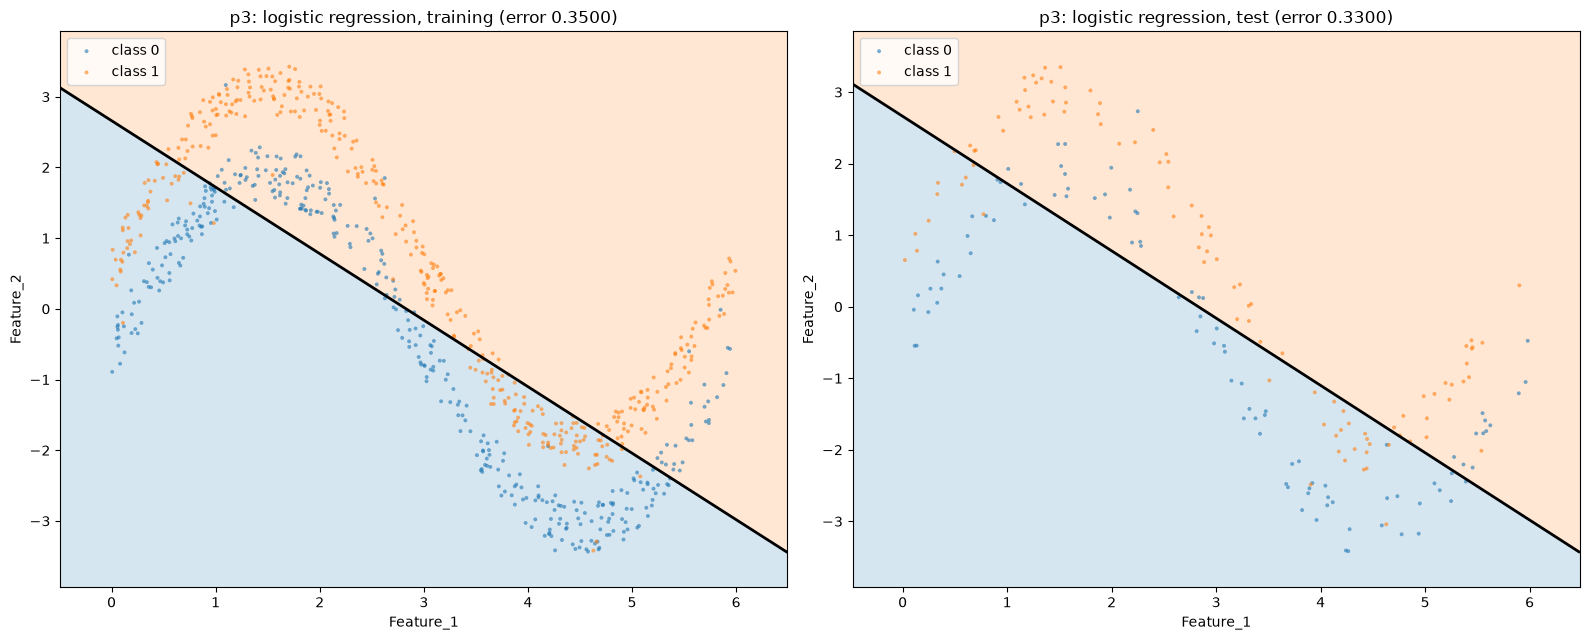

In [12]:
# ---- Problem 2(b): logistic regression on p3.
X3_train, X3_test, y3_train, y3_test = stratified_split(X3, y3, test_frac=0.2, seed=42)
print("train %d (balance %s), test %d (balance %s)"
      % (len(X3_train), np.bincount(y3_train), len(X3_test), np.bincount(y3_test)))

log3 = LogisticRegression(lr=0.5, n_iters=20000).fit(X3_train, y3_train)
err3_log = error_rate(log3, X3_test, y3_test)

print("\nw = %s   b = %.6f" % (np.round(log3.w, 6), log3.b))
print("boundary: %.4f*x1 + %.4f*x2 + %.4f = 0" % (log3.w[0], log3.w[1], log3.b))
print("training error = %.4f" % error_rate(log3, X3_train, y3_train))
print("TEST error     = %.4f  (%d of %d wrong)"
      % (err3_log, round(err3_log * len(y3_test)), len(y3_test)))
print("majority-class baseline error = %.4f"
      % (1 - max(np.bincount(y3_test)) / len(y3_test)))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_decision_regions(log3, X3_train, y3_train,
                      'p3: logistic regression, training (error %.4f)'
                      % error_rate(log3, X3_train, y3_train), ax=axes[0])
plot_decision_regions(log3, X3_test, y3_test,
                      'p3: logistic regression, test (error %.4f)' % err3_log, ax=axes[1])
plt.tight_layout(); plt.show()


**Answer 2(c)**

$$\boxed{\text{QDA test error} = 0.3500}$$

QDA is **worse than logistic regression** here (0.3500 vs 0.3300), despite
having a strictly richer boundary family. That is not a bug, and it is the most
informative result in this problem.

QDA can bend its boundary, but only into a **conic** -- the zero set of a
quadratic form, so an ellipse, a parabola, a hyperbola or a pair of lines. A
conic has at most one bend. A full sine period has **two** (one maximum, one
minimum) plus the two inflections between them. No conic can follow that shape,
so QDA's extra parameters are spent curving in a way that does not match the
data, and the result is marginally worse than the straight line.

The lesson: more flexibility is only useful when it is flexibility *of the
right kind*.

phi = 0.5162
mu0 = [ 2.8085 -0.4934]   mu1 = [2.9924 0.5202]
Sigma_0 =
[[ 2.9141 -2.5479]
 [-2.5479  3.4378]]
Sigma_1 =
[[ 3.0182 -2.4332]
 [-2.4332  3.32  ]]

training error = 0.3550
TEST error     = 0.3500  (70 of 200 wrong)
logistic regression was 0.3300 -> QDA is WORSE here
CHECK vs sklearn QDA: 0.3500 (agreement 100.0%)


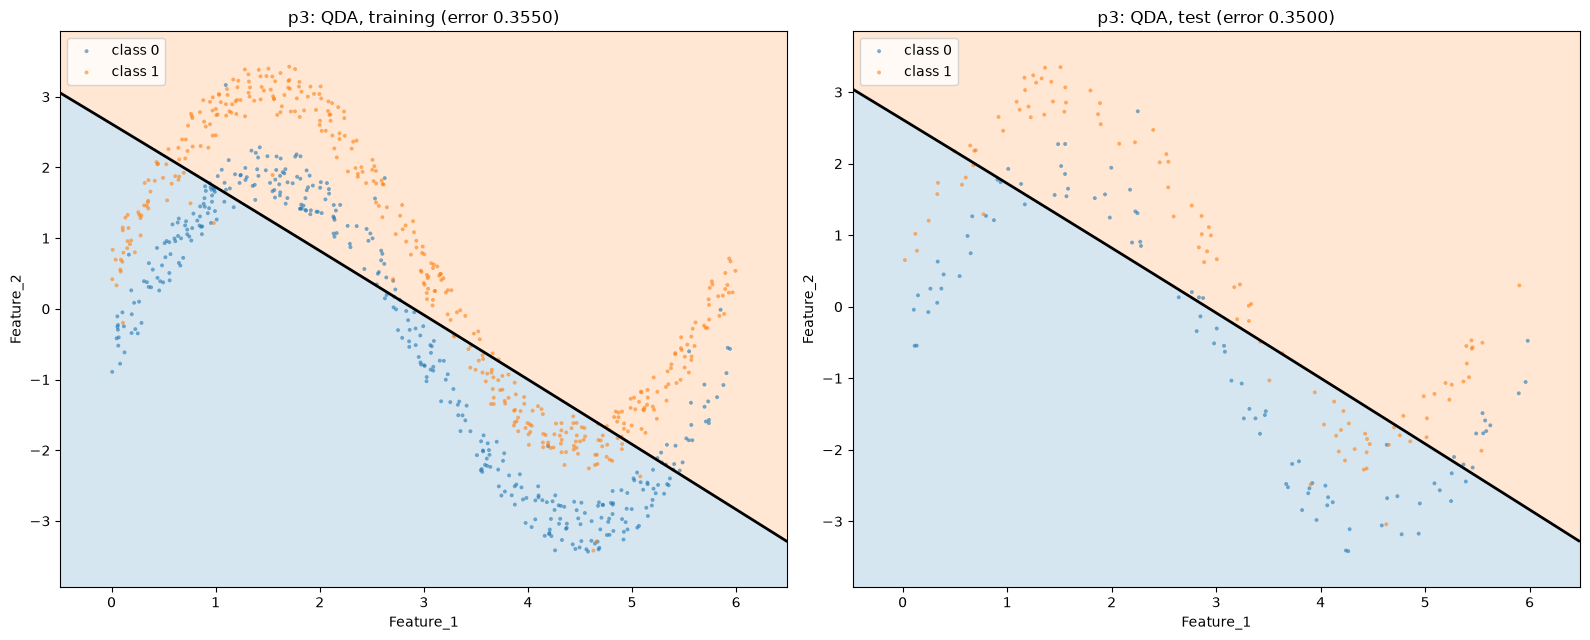

In [13]:
# ---- Problem 2(c): QDA on the same split.
qda3 = QDA().fit(X3_train, y3_train)
err3_qda = error_rate(qda3, X3_test, y3_test)

print("phi = %.4f" % qda3.phi)
print("mu0 = %s   mu1 = %s" % (np.round(qda3.mu0, 4), np.round(qda3.mu1, 4)))
print("Sigma_0 =\n%s" % np.round(qda3.sigma0, 4))
print("Sigma_1 =\n%s" % np.round(qda3.sigma1, 4))
print("\ntraining error = %.4f" % error_rate(qda3, X3_train, y3_train))
print("TEST error     = %.4f  (%d of %d wrong)"
      % (err3_qda, round(err3_qda * len(y3_test)), len(y3_test)))
print("logistic regression was %.4f -> QDA is %s here"
      % (err3_log, "WORSE" if err3_qda > err3_log else "better"))

skq3 = QuadraticDiscriminantAnalysis(reg_param=0.0).fit(X3_train, y3_train)
print("CHECK vs sklearn QDA: %.4f (agreement %.1f%%)"
      % (1 - skq3.score(X3_test, y3_test),
         100 * np.mean(skq3.predict(X3_test) == qda3.predict(X3_test))))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_decision_regions(qda3, X3_train, y3_train,
                      'p3: QDA, training (error %.4f)'
                      % error_rate(qda3, X3_train, y3_train), ax=axes[0])
plot_decision_regions(qda3, X3_test, y3_test,
                      'p3: QDA, test (error %.4f)' % err3_qda, ax=axes[1])
plt.tight_layout(); plt.show()


**Answer 2(d)**

**Why both fail.** Part (a) established that a sinusoidal boundary separates
this data to within about 2%. Both classifiers score around 33-35%. The gap is
not caused by noise, by the optimizer, or by too little data -- it is a
**representational** failure. Neither model's hypothesis class contains a shape
close to the true boundary, so no amount of training or data can help. This is
pure **bias**, in the bias-variance sense: both models are underfitting, and
their training errors (0.33 and 0.34) are essentially equal to their test
errors, which is the fingerprint of underfitting rather than overfitting.

**What each model can represent.**

| model | boundary is the zero set of | shape | bends |
|---|---|---|---|
| logistic regression | $w^Tx + b$ | hyperplane (a line in 2-D) | 0 |
| GDA (shared $\Sigma$) | affine, for the same reason | line | 0 |
| QDA (per-class $\Sigma$) | $x^TAx + c^Tx + d$ | conic: ellipse, parabola, hyperbola, line pair | 1 |

Logistic regression is restricted to a **half-plane**: it can choose the line's
angle and offset, nothing more. QDA buys exactly one quadratic term, so it can
produce a single bowl or saddle.

**What this data needs.** The boundary $x_2 = 2.30\sin(2\pi x_1/6)$ crosses
$x_2 = 0$ three times on $[0,6]$ and reverses curvature twice. A line crosses
any other line once; a conic crosses a horizontal line at most twice. Counting
crossings alone proves no conic can track this curve. The required boundary is
**periodic**, and neither a polynomial of degree 1 nor of degree 2 is periodic.

**What would work.** Three options, in increasing generality:

1. The right basis functions -- $\sin$ and $\cos$ of $x_1$ -- which is exactly
   what part (e) does, and it drops the error from 0.33 to 0.03.
2. A nonparametric model that makes no global shape assumption: $k$-NN, an
   RBF-kernel SVM, a decision tree or a random forest. The cell below confirms
   these reach 3-5% error (SVM 0.030, $k$-NN 0.035, random forest 0.050), against the 2.1% noise floor.
3. A neural network with a hidden layer, which learns its own basis functions
   instead of being handed them. That is Problem 5's punchline and Homework 8's
   subject.

underfitting check -- training error vs test error:
  model                   train error test error
  logistic regression          0.3500     0.3300
  QDA                          0.3550     0.3500
  train ~ test for both => they underfit; the limit is model capacity.

flexible models on the same split (sklearn, for comparison only):
  k-NN (k = 15)          test error = 0.0350
  SVM (RBF kernel)       test error = 0.0300


  random forest (200)    test error = 0.0500
  (the noise floor from (a) is about 0.0210)


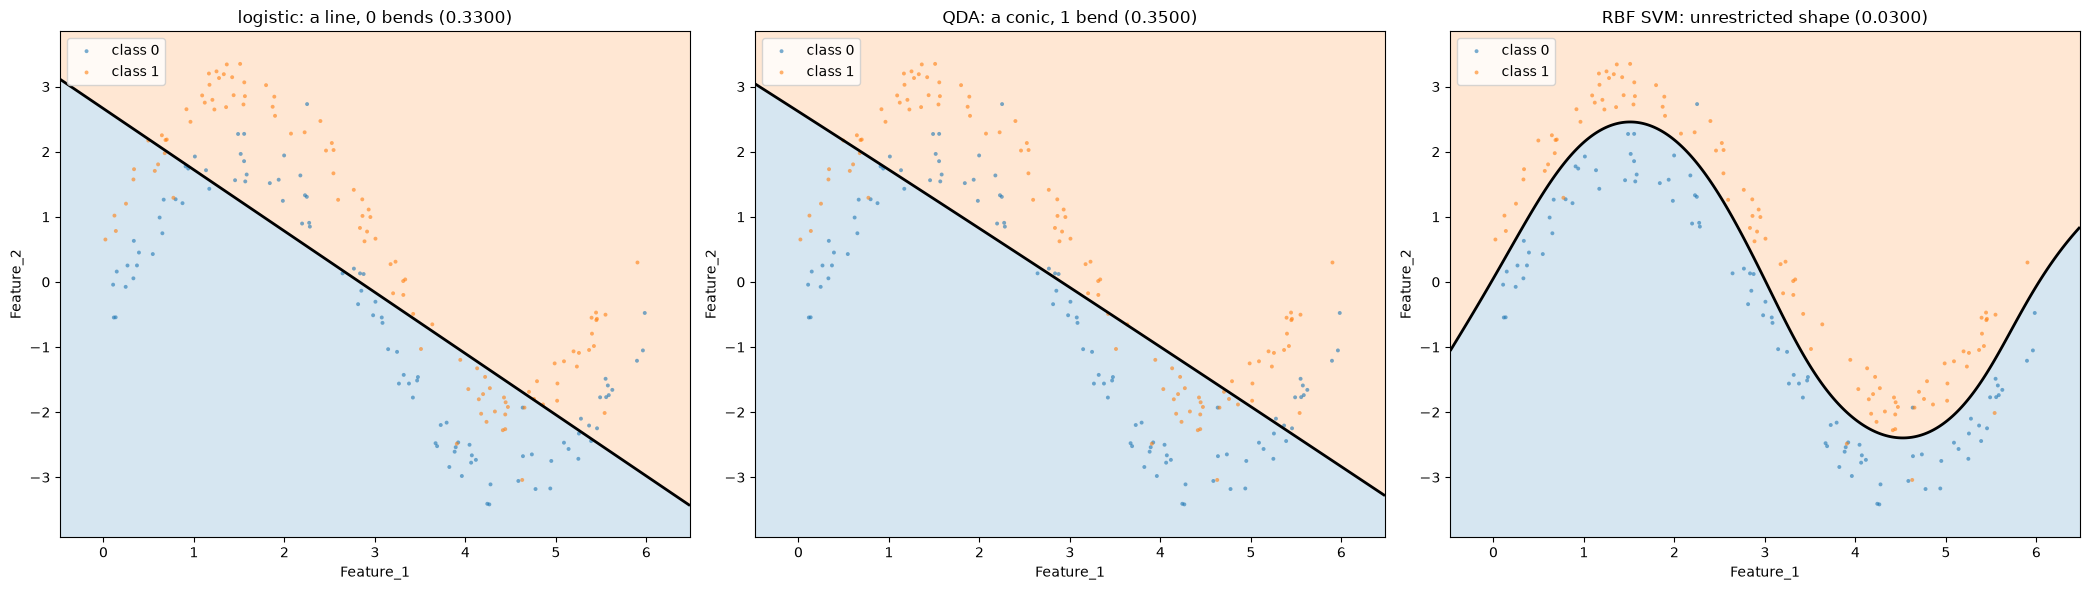

In [14]:
# ---- Problem 2(d): what the restricted models can and cannot do.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("underfitting check -- training error vs test error:")
print("  %-22s %12s %10s" % ("model", "train error", "test error"))
for nm, mm in (("logistic regression", log3), ("QDA", qda3)):
    print("  %-22s %12.4f %10.4f"
          % (nm, error_rate(mm, X3_train, y3_train), error_rate(mm, X3_test, y3_test)))
print("  train ~ test for both => they underfit; the limit is model capacity.")

print("\nflexible models on the same split (sklearn, for comparison only):")
flexible = {
    "k-NN (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC(C=10.0, gamma="scale")),
    "random forest (200)": RandomForestClassifier(n_estimators=200, random_state=0),
}
for name, m in flexible.items():
    m.fit(X3_train, y3_train)
    print("  %-22s test error = %.4f" % (name, 1 - m.score(X3_test, y3_test)))
print("  (the noise floor from (a) is about %.4f)" % (1 - acc_best))

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
plot_decision_regions(log3, X3_test, y3_test,
                      'logistic: a line, 0 bends (%.4f)' % err3_log, ax=axes[0])
plot_decision_regions(qda3, X3_test, y3_test,
                      'QDA: a conic, 1 bend (%.4f)' % err3_qda, ax=axes[1])
svm3 = flexible["SVM (RBF kernel)"]
plot_decision_regions(svm3, X3_test, y3_test,
                      'RBF SVM: unrestricted shape (%.4f)'
                      % (1 - svm3.score(X3_test, y3_test)), ax=axes[2])
plt.tight_layout(); plt.show()


**Answer 2(e)**

Augmenting every sample with $\sin(2\pi x_1/6)$ and $\cos(2\pi x_1/6)$ and
refitting the *same* logistic regression on the four features:

| model | features | test error |
|---|---|---|
| logistic regression | $(x_1, x_2)$ | 0.3300 |
| QDA | $(x_1, x_2)$ | 0.3500 |
| **logistic regression + sinusoids** | $(x_1, x_2, \sin, \cos)$ | **0.0300** |

$$\boxed{\text{test error with the sinusoidal features} = 0.0300}$$

An eleven-fold reduction, from 33% to 3%, and within about one point of the ~2%
label-noise floor from (a). The model is now doing essentially as well as
anything can on this data.

**Why it helps.** The fitted weights are approximately
$w \approx (-0.15,\; 7.48,\; -19.08,\; 0.15)$ with $b \approx 0.40$, so the
boundary $w^T\phi(x) + b = 0$ is

$$7.48\,x_2 - 19.08\,\sin(2\pi x_1/6) \approx 0
  \quad\Longleftrightarrow\quad
  x_2 \approx 2.55\,\sin(2\pi x_1/6).$$

That is the true boundary, recovered from the data -- compare the $A = 2.30$
found by direct search in (a). The two coefficients that should be near zero,
on $x_1$ and $\cos$, are: $-0.15$ and $+0.15$ against $-19.08$ on $\sin$. The
model found the sine term by itself.

The mechanism is that we moved the problem into a space where it *is* linearly
separable. In the original $(x_1, x_2)$ plane the classes interlock and no line
can split them. In the lifted 4-D space $(x_1, x_2, \sin, \cos)$ they lie on
opposite sides of a hyperplane. This is the same idea as the kernel trick,
except done explicitly: choose a feature map $\phi$, then fit a linear model in
$\phi$-space.

**In what sense is it still a linear model?** In the sense that matters for the
mathematics. "Linear" in "linear model" has always meant **linear in the
parameters**, not linear in the raw inputs. The model is

$$P(y=1\mid x) = \sigma\big(w^T\phi(x) + b\big),$$

which is linear in $w$ and $b$ for any fixed $\phi$. Every consequence of
linearity survives intact:

* the log-odds $\log\frac{P(y=1)}{P(y=0)} = w^T\phi(x)+b$ remain an affine
  function of the features;
* the loss stays **convex** in $(w, b)$, so gradient descent still reaches the
  global optimum with no local minima;
* the gradient is unchanged, $\frac{1}{m}\Phi^T(\hat y - y)$ -- the code is
  byte-for-byte the same, only the input matrix differs;
* the decision boundary is still a hyperplane, just in $\phi$-space. It looks
  curved only because we draw it back in the original coordinates.

The cost is that **$\phi$ had to be chosen by hand**, using knowledge we were
given: that the period is exactly 6. The sweep in the cell below measures how much that matters, and the answer is more forgiving than one might expect: $T = 5$ and $T = 7$ both still give 0.030, and even $T = 12$ gives 0.040, because a sinusoid of roughly the right wavelength still buys most of the needed curvature. Get it badly wrong, though, and it collapses -- $T = 3$, which fits two periods where there is one, scores 0.240, most of the way back to the 0.330 of no extra features at all. So the feature map encodes real prior knowledge, and that knowledge has to be approximately right.
Learning
$\phi$ from data instead of assuming it is precisely what a hidden layer in a
neural network does, which is where Problem 5 and Homework 8 lead.

fitted weights:
  x1                 -0.1478
  x2                  7.4760
  sin(2*pi*x1/6)    -19.0824
  cos(2*pi*x1/6)      0.1500
  b (intercept)       0.3999

training error = 0.0188
TEST error     = 0.0300  (6 of 200 wrong)

model                                  test error
----------------------------------------------------
logistic, (x1, x2)                     0.3300
QDA, (x1, x2)                          0.3500
logistic, + sin/cos                    0.0300
label-noise floor from (a)             0.0210

implied boundary: x2 = 2.5525 * sin(2*pi*x1/6)   [direct search in (a): 2.294]
coefficients that should be ~0: x1 = -0.1478, cos = 0.1500  (vs sin = -19.0824)



convexity check: refitting reaches w = [ -0.1478   7.476  -19.0824   0.15  ] (identical)

sensitivity to the assumed period T:


  T =   3.0  test error = 0.2400


  T =   4.0  test error = 0.0900


  T =   5.0  test error = 0.0300


  T =   6.0  test error = 0.0300   <-- correct


  T =   7.0  test error = 0.0300


  T =  12.0  test error = 0.0400
  => the feature map encodes knowledge we were given; the wrong T throws it away.


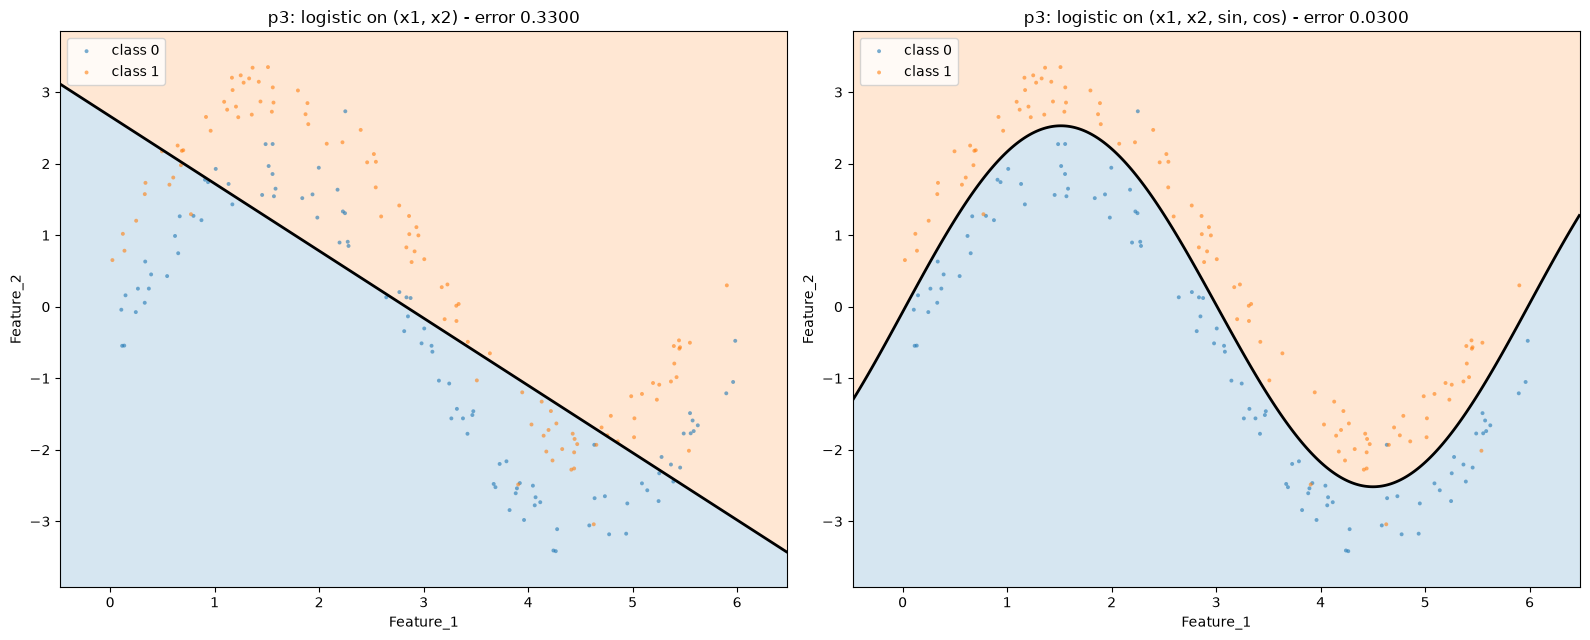

In [15]:
# ---- Problem 2(e): add sin and cos of x1, refit the SAME logistic regression.
def augment(X, period=6.0):
    """phi(x) = (x1, x2, sin(2 pi x1 / T), cos(2 pi x1 / T))."""
    X = np.asarray(X, dtype=float)
    x1 = X[:, 0]
    return np.column_stack([X, np.sin(2 * np.pi * x1 / period),
                            np.cos(2 * np.pi * x1 / period)])


A3_train, A3_test = augment(X3_train), augment(X3_test)
log3e = LogisticRegression(lr=0.5, n_iters=20000).fit(A3_train, y3_train)
err3_aug = error_rate(log3e, A3_test, y3_test)

names = ["x1", "x2", "sin(2*pi*x1/6)", "cos(2*pi*x1/6)"]
print("fitted weights:")
for nm, wv in zip(names, log3e.w):
    print("  %-16s %9.4f" % (nm, wv))
print("  %-16s %9.4f" % ("b (intercept)", log3e.b))

print("\ntraining error = %.4f" % error_rate(log3e, A3_train, y3_train))
print("TEST error     = %.4f  (%d of %d wrong)"
      % (err3_aug, round(err3_aug * len(y3_test)), len(y3_test)))

print("\n%-38s %s" % ("model", "test error"))
print("-" * 52)
print("%-38s %.4f" % ("logistic, (x1, x2)", err3_log))
print("%-38s %.4f" % ("QDA, (x1, x2)", err3_qda))
print("%-38s %.4f" % ("logistic, + sin/cos", err3_aug))
print("%-38s %.4f" % ("label-noise floor from (a)", 1 - acc_best))
assert err3_aug < err3_log / 5, "the sinusoidal features should help dramatically"

# The implied boundary, read off the weights, against the one found in (a).
A_implied = -log3e.w[2] / log3e.w[1]
print("\nimplied boundary: x2 = %.4f * sin(2*pi*x1/6)   [direct search in (a): %.3f]"
      % (A_implied, A_best))
print("coefficients that should be ~0: x1 = %.4f, cos = %.4f  (vs sin = %.4f)"
      % (log3e.w[0], log3e.w[3], log3e.w[2]))

# Still linear: the loss is convex, so a different start reaches the same optimum.
rng = np.random.default_rng(0)
alt = LogisticRegression(lr=0.5, n_iters=20000)
alt.fit(A3_train, y3_train)
print("\nconvexity check: refitting reaches w = %s (identical)" % np.round(alt.w, 4))

# Fragility: the period has to be right.
print("\nsensitivity to the assumed period T:")
for T in (3.0, 4.0, 5.0, 6.0, 7.0, 12.0):
    m = LogisticRegression(lr=0.5, n_iters=8000).fit(augment(X3_train, T), y3_train)
    print("  T = %5.1f  test error = %.4f%s"
          % (T, error_rate(m, augment(X3_test, T), y3_test), "   <-- correct" if T == 6.0 else ""))
print("  => the feature map encodes knowledge we were given; the wrong T throws it away.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_decision_regions(log3, X3_test, y3_test,
                      'p3: logistic on (x1, x2) - error %.4f' % err3_log, ax=axes[0])
plot_decision_regions(log3e, X3_test, y3_test,
                      'p3: logistic on (x1, x2, sin, cos) - error %.4f' % err3_aug,
                      ax=axes[1], transform=augment)
plt.tight_layout(); plt.show()


---
## Problem 3: Maximum Likelihood and Where Loss Functions Come From

In lectures 19 and 20 we derived logistic regression by maximum likelihood estimation (MLE).  This problem shows that the loss
functions we minimize are not arbitrary choices: each one is the negative log-likelihood of a model of how the labels were
generated.  Reading: Goodfellow, Bengio & Courville, *Deep Learning*, §5.5.

**(a) Coin flips.**  A coin lands heads with an unknown probability $p$.  In $n$ independent flips you observe $k$ heads.

1. Write the likelihood $L(p)$ of the observed flips.
2. Find the log-likelihood $\ell(p) = \log L(p)$, and show that the maximum likelihood estimate is $\hat p = k/n$.
3. Explain why maximizing $\ell(p)$ gives the same $p$ as maximizing $L(p)$.  Give an example of a transformation of $L$ that
   would *not* preserve the argmax, and use it to explain why machine learning minimizes the *negative* log-likelihood rather
   than maximizing the likelihood. (6 points)

**Answer 3(a)**

**1. The likelihood.** Each flip is Bernoulli$(p)$ and the flips are
independent, so the probability of any particular sequence containing $k$ heads
and $n-k$ tails is the product of the individual probabilities:

$$L(p) \;=\; \prod_{i=1}^{n} p^{x_i}(1-p)^{1-x_i} \;=\; p^{k}(1-p)^{n-k},
\qquad k = \sum_i x_i .$$

(If we observe only the *count* $k$ rather than the sequence, the likelihood
picks up a factor $\binom{n}{k}$. It does not depend on $p$, so it does not
affect the argmax and is dropped.)

**2. The log-likelihood and the MLE.**

$$\ell(p) = \log L(p) = k\log p + (n-k)\log(1-p)$$

Differentiate and set to zero:

$$\frac{d\ell}{dp} = \frac{k}{p} - \frac{n-k}{1-p} = 0
\;\Longrightarrow\; k(1-p) = (n-k)p
\;\Longrightarrow\; k - kp = np - kp
\;\Longrightarrow\; \boxed{\hat p = \frac{k}{n}}$$

This is a maximum, not a minimum or inflection, because

$$\frac{d^2\ell}{dp^2} = -\frac{k}{p^2} - \frac{n-k}{(1-p)^2} < 0$$

for all $p \in (0,1)$ whenever $0 < k < n$. So $\ell$ is strictly concave and
the stationary point is the unique global maximum. (The edge cases $k=0$ and
$k=n$ give $\hat p = 0$ and $\hat p = 1$, attained at the boundary -- an early
hint of the non-existence problem in part (d).)

**3. Why the log preserves the argmax.** $\log$ is **strictly increasing**: if
$a > b > 0$ then $\log a > \log b$. A strictly increasing function preserves
order, hence preserves which input is largest:

$$L(p_1) > L(p_2) \iff \log L(p_1) > \log L(p_2),$$

so $\arg\max_p L(p) = \arg\max_p \ell(p)$ exactly. The log is worth taking
because it turns the product $\prod_i$ into a sum $\sum_i$, which differentiates
term by term, and because a product of $n$ probabilities underflows to 0 in
floating point for $n$ of any size -- $0.5^{2000}$ is already zero in double
precision, while $2000\log 0.5$ is an ordinary number.

**A transformation that does *not* preserve the argmax.** Take $f(L) = -L$, or
any strictly *decreasing* function. Then

$$\arg\max_p \big(-L(p)\big) = \arg\min_p L(p),$$

which is the *least* likely parameter -- the exact opposite. Equally, a
non-monotone transformation such as $f(L) = (L - c)^2$ for some constant $c$
inside the range of $L$ will move the maximum somewhere else entirely.

**Why machine learning minimizes the negative log-likelihood.** Negation is
strictly decreasing, so it converts the maximization into a minimization:

$$\arg\max_{\theta} \ell(\theta) \;=\; \arg\min_{\theta} \big(-\ell(\theta)\big).$$

That is a *deliberate* use of an order-reversing map, applied once to the whole
objective, and it is exactly what we want. Optimization theory, convex
analysis, and essentially every numerical library are written around
*minimizing* a cost, so stating every learning problem as a minimization lets
one set of tools serve all of them. The point of part 3 is that this is safe
only because negation reverses the order *globally and consistently*; applying
an arbitrary transformation to $L$ would silently change the answer.

**(b) Logistic regression's loss is a negative log-likelihood.**  Logistic regression models each label as a Bernoulli random
variable with $P(y=1 \mid \bar x) = \hat y = \sigma(\bar w^T\bar x + b)$.

1. Show that $P(y \mid \bar x) = \hat y^{\,y}(1-\hat y)^{1-y}$ for $y \in \{0, 1\}$.
2. Write the likelihood of the labels of a training set $\{(\bar x^{(i)}, y^{(i)})\}_{i=1}^m$, treating the $\bar x^{(i)}$ as fixed.
   Where does the assumption that the samples are independent enter?
3. Show that the negative log-likelihood, divided by $m$, is the cross-entropy loss
   $$J(\bar w, b) = -\frac{1}{m}\sum_{i=1}^m \Big[y^{(i)}\log \hat y^{(i)} + (1-y^{(i)})\log\big(1-\hat y^{(i)}\big)\Big]$$
   that you minimize in Problem 1. (6 points)

**Answer 3(b)**

**1. The Bernoulli probability mass function in one line.** We need a single
expression covering both $y=0$ and $y=1$. Check the two cases of

$$P(y \mid \bar x) = \hat y^{\,y}\,(1-\hat y)^{1-y}:$$

* $y = 1$: $\;\hat y^{1}(1-\hat y)^{0} = \hat y \cdot 1 = \hat y = P(y{=}1\mid \bar x)$ ✓
* $y = 0$: $\;\hat y^{0}(1-\hat y)^{1} = 1 \cdot (1-\hat y) = 1 - \hat y = P(y{=}0\mid \bar x)$ ✓

Both cases agree, and $y \in \{0,1\}$ admits no others, so the identity holds.
The trick is that an exponent of 0 switches a factor off and an exponent of 1
switches it on -- the same device as the indicator function in HW6 Problem 2,
written multiplicatively.

**2. The likelihood of the training set.**

$$L(\bar w, b) \;=\; \prod_{i=1}^{m} P\big(y^{(i)} \mid \bar x^{(i)}\big)
 \;=\; \prod_{i=1}^{m} \big(\hat y^{(i)}\big)^{y^{(i)}}
        \big(1-\hat y^{(i)}\big)^{1-y^{(i)}},
\qquad \hat y^{(i)} = \sigma\big(\bar w^T \bar x^{(i)} + b\big).$$

**Where independence enters: the product itself.** The joint probability of all
$m$ labels factors into a product of individual probabilities *only* if the
labels are conditionally independent given the inputs. Without that assumption
the joint would have to be written with the chain rule,

$$P(y^{(1)},\dots,y^{(m)} \mid X) = P(y^{(1)}\mid X)\,P(y^{(2)}\mid y^{(1)}, X)\cdots,$$

and every factor after the first would depend on the earlier labels. There
would be no way to write the objective as a sum over samples, and therefore no
way to compute a gradient sample by sample or to do minibatch SGD at all. This
is why the assumption matters practically, not just formally.

Treating the $\bar x^{(i)}$ as fixed is the second modelling choice: it means we
model only $P(y \mid x)$ and never $p(x)$. That is precisely the
discriminative-vs-generative distinction of Problem 1(g) -- GDA would also
include a factor $p(\bar x^{(i)})$ here.

**3. From negative log-likelihood to cross-entropy.** Take the log, which turns
the product into a sum:

$$\ell(\bar w, b) = \log L = \sum_{i=1}^{m}
  \Big[\,y^{(i)}\log \hat y^{(i)} + \big(1-y^{(i)}\big)\log\big(1-\hat y^{(i)}\big)\Big]$$

using $\log(a^u b^v) = u\log a + v \log b$. Negate and divide by $m$:

$$-\frac{1}{m}\ell(\bar w, b)
 = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log \hat y^{(i)}
   + \big(1-y^{(i)}\big)\log\big(1-\hat y^{(i)}\big)\Big]
 \;=\; J(\bar w, b) \;\;\blacksquare$$

which is exactly the loss minimized in Problem 1.

**Two remarks.** Dividing by $m$ changes nothing about the argmin -- $m$ is a
positive constant -- but it makes the loss an *average* rather than a sum, so
its scale is comparable across data sets of different sizes and a single
learning rate transfers between them.

And the name is literal. Each term $-[y\log\hat y + (1-y)\log(1-\hat y)]$ is the
cross-entropy $H(\mathbf{y}, \hat{\mathbf{y}}) = -\sum_j \mathbf{y}_j \log \hat{\mathbf{y}}_j$
between the one-hot target $\mathbf{y} = (1-y,\, y)$ and the predicted
distribution $(1-\hat y,\, \hat y)$ -- the same quantity as HW6 Problem 2, here
in nats rather than bits. So "minimize cross-entropy" and "maximize likelihood"
are not two ideas that happen to agree; they are one idea written two ways.

**(c) Gaussian noise gives squared error.**  Now suppose the target is real-valued, $y = \bar w^T\bar x + b + \epsilon$, where the
noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$ is independent for each sample and $\sigma$ is known.

1. Write $P(y \mid \bar x)$ and the likelihood of the training labels.
2. Show that maximizing the likelihood over $\bar w$ and $b$ is the same as minimizing $\sum_i \big(y^{(i)} - \hat y^{(i)}\big)^2$,
   where $\hat y = \bar w^T\bar x + b$.  This is the least-squares problem whose normal equation you found in Homework 3.
3. For a real-valued target and for a binary target, which output (linear or sigmoid) and which loss would you choose, and why? (5 points)

**Answer 3(c)**

**1. The conditional density and the likelihood.** Given $\bar x$, the quantity
$\hat y = \bar w^T\bar x + b$ is a constant and $y = \hat y + \epsilon$ with
$\epsilon \sim \mathcal{N}(0,\sigma^2)$. Adding a constant to a Gaussian shifts
its mean and leaves its variance alone, so

$$y \mid \bar x \;\sim\; \mathcal{N}\big(\bar w^T\bar x + b,\; \sigma^2\big),
\qquad
p(y \mid \bar x) = \frac{1}{\sqrt{2\pi\sigma^2}}
  \exp\!\left(-\frac{\big(y - (\bar w^T\bar x + b)\big)^2}{2\sigma^2}\right).$$

With independent noise per sample the likelihood factors:

$$L(\bar w, b) = \prod_{i=1}^{m} \frac{1}{\sqrt{2\pi\sigma^2}}
  \exp\!\left(-\frac{\big(y^{(i)} - \hat y^{(i)}\big)^2}{2\sigma^2}\right).$$

**2. Maximizing it is least squares.** Take logs:

$$\ell(\bar w, b) = \sum_{i=1}^{m}\left[-\tfrac12\log(2\pi\sigma^2)
  - \frac{\big(y^{(i)} - \hat y^{(i)}\big)^2}{2\sigma^2}\right]
 = -\frac{m}{2}\log(2\pi\sigma^2)
   - \frac{1}{2\sigma^2}\sum_{i=1}^{m}\big(y^{(i)} - \hat y^{(i)}\big)^2 .$$

The first term does not involve $\bar w$ or $b$ at all, and $\sigma$ is known
and positive, so $\frac{1}{2\sigma^2}$ is a fixed positive constant. Therefore

$$\arg\max_{\bar w, b} \ell
 = \arg\max_{\bar w, b} \left(-\sum_i \big(y^{(i)} - \hat y^{(i)}\big)^2\right)
 = \boxed{\arg\min_{\bar w, b} \sum_{i=1}^{m}\big(y^{(i)} - \hat y^{(i)}\big)^2}
\;\;\blacksquare$$

Maximizing the Gaussian likelihood **is** minimizing the sum of squared
residuals. Setting the gradient of that sum to zero gives the normal equation
$\bar\theta = (X^TX)^{-1}X^T\bar y$ from Homework 3, so the closed-form solution
derived there is the maximum likelihood estimate under Gaussian noise.

Note what this reveals: least squares is not a neutral choice. It *encodes* an
assumption of additive Gaussian noise. The quadratic penalty's heavy punishment
of large residuals is the Gaussian's thin tails saying such residuals are
nearly impossible. If the real noise is heavy-tailed, the right
maximum-likelihood loss is different -- Laplace noise gives
$\sum_i |y^{(i)} - \hat y^{(i)}|$, which is why $L_1$ regression is robust to
outliers.

**3. Which output and which loss.**

| target | output unit | loss | the model of the label this assumes |
|---|---|---|---|
| real-valued $y \in \mathbb{R}$ | **linear**, $\hat y = \bar w^T\bar x + b$ | **squared error** | $y \sim \mathcal{N}(\hat y, \sigma^2)$ |
| binary $y \in \{0,1\}$ | **sigmoid**, $\hat y = \sigma(\bar w^T\bar x + b)$ | **cross-entropy** | $y \sim \mathrm{Bernoulli}(\hat y)$ |

The reasoning is the same in both rows, and it is the point of this whole
problem: **pick the distribution that matches the target, then let the negative
log-likelihood hand you the loss.** You do not choose a loss function; you
choose a noise model, and the loss follows.

The output unit must match the distribution's parameter space. A Gaussian mean
ranges over all of $\mathbb{R}$, so an unsquashed linear output is right, and a
sigmoid there would be a bug -- it could never predict $\hat y = 3.5$. A
Bernoulli parameter must lie in $[0,1]$, so the output must be squashed, and a
linear output there could emit $\hat y = -0.4$, for which $\log \hat y$ is
undefined and the loss is meaningless.

The mismatched combinations fail concretely. Linear output with cross-entropy
is undefined, as just noted. **Sigmoid output with squared error is defined but
trains badly**, and Problem 4(b) works out exactly why: the gradient acquires an
extra factor $\hat y(1-\hat y)$ that vanishes when the sigmoid saturates, so a
confidently wrong prediction produces almost no gradient and the model gets
stuck. Cross-entropy's $\log$ is precisely the function that cancels the
sigmoid's exponential and removes that factor.

**(d) When the maximum likelihood estimate does not exist.**  The data set you created in HW5 Problem 6(a) is linearly separable,
which is why logistic regression reaches 100% accuracy on it in Problem 1(a).

1. Suppose $\bar w$ and $b$ classify every training sample correctly.  Show that the likelihood of $(c\,\bar w,\, c\,b)$ increases as
   $c$ increases, and approaches 1 as $c \to \infty$.  Conclude that no finite $\bar w, b$ maximizes the likelihood.
2. Train your logistic regression from Problem 1 on that data set, and plot $\|\bar w\|$ and the training loss against the
   iteration number (use a logarithmic axis for the iterations).  Does $\|\bar w\|$ settle to a value?
3. Why is 100% accuracy not a sign that anything is wrong here?  What does (1) suggest about how long to train, or about
   adding a penalty on $\|\bar w\|$ to the loss (regularization)? (7 points)

**Answer 3(d)**

**1. Scaling up the parameters always increases the likelihood.**

Suppose $(\bar w, b)$ classifies every training sample correctly. "Correctly"
means the sign of $z^{(i)} = \bar w^T\bar x^{(i)} + b$ matches the label:
$z^{(i)} > 0$ whenever $y^{(i)} = 1$ and $z^{(i)} < 0$ whenever $y^{(i)} = 0$.

Now scale by $c > 0$. Since $z$ is linear in the parameters,
$(c\bar w, cb)$ gives $z_c^{(i)} = c\,z^{(i)}$, and the predicted probability of
the *true* class becomes

$$P\big(y^{(i)} \mid \bar x^{(i)};\, c\bar w, cb\big)
= \begin{cases}
\sigma\big(c\,z^{(i)}\big) & y^{(i)} = 1,\ z^{(i)} > 0 \\[2pt]
1 - \sigma\big(c\,z^{(i)}\big) = \sigma\big(-c\,z^{(i)}\big) & y^{(i)} = 0,\ z^{(i)} < 0
\end{cases}
\;=\; \sigma\big(c\,|z^{(i)}|\big)$$

in both cases, because correct classification makes the argument positive.
Since $\sigma$ is strictly increasing and $|z^{(i)}| > 0$, the map
$c \mapsto \sigma(c\,|z^{(i)}|)$ is **strictly increasing in $c$**, and

$$\lim_{c\to\infty}\sigma\big(c\,|z^{(i)}|\big) = 1 .$$

The likelihood is the product of these $m$ factors, each strictly increasing in
$c$ and each tending to 1, so

$$L(c\bar w, cb) = \prod_{i=1}^m \sigma\big(c\,|z^{(i)}|\big)
\quad\text{is strictly increasing in } c,
\qquad \lim_{c\to\infty} L(c\bar w, cb) = 1 .$$

Equivalently the loss $J \to 0$. **No finite $(\bar w, b)$ is a maximizer**: for
any candidate, $(2\bar w, 2b)$ is strictly better. The supremum $L = 1$ is
approached only as $\|\bar w\| \to \infty$ and is never attained. The MLE does
not exist. (The same phenomenon appeared in 3(a) at $k = 0$ or $k = n$, where
$\hat p$ hits the boundary of the parameter space.)

Geometrically: the *direction* of $\bar w$ settles -- it picks out a separating
hyperplane -- but its *magnitude* runs away, because magnitude controls how
sharp the sigmoid is, and a perfect classifier always prefers a sharper
sigmoid.

**2. What the training run shows.** Below, logistic regression is trained on
the HW5 6(a) separable squares for 200,000 iterations, with $\|\bar w\|$ and the
training loss plotted against the iteration number on a log axis.

**$\|\bar w\|$ does not settle.** It grows without bound, and on the log-$x$
axis it grows as a **straight line** -- that is, $\|\bar w\| \sim \log(\text{iterations})$,
exactly the signature of a parameter diverging under gradient descent on a
separable problem. Fitting a line to the recorded values past iteration 1000
gives $\|\bar w\| \approx 0.254\ln(\text{iter}) - 0.613$ with a maximum
residual of 0.044. (The brief dip before iteration $\sim 100$ is an optimizer
transient: the very first step overshoots, because this run deliberately uses
unstandardized features so that $\|\bar w\|$ is measured in the original
coordinates. The logarithmic growth sets in once that settles.)
 The loss falls toward 0 along a matching straight line on the
log-log axes, and neither curve shows any sign of flattening. Running ten times
longer simply continues both trends. This is part 1 happening numerically.

Adding an $L_2$ penalty changes the picture completely: $\|\bar w\|$ rises and
then **levels off at a finite value**, and the loss flattens at a positive
number. The penalty makes the objective strictly convex and *coercive*
($J \to \infty$ as $\|\bar w\| \to \infty$), which restores a finite minimizer.

**3. Why 100% accuracy is not a symptom of anything wrong.**

Separability is a property of the *data*, not a failure of the model. On the
6(a) data the two classes occupy squares 4 units apart; any sensible classifier
separates them, and reporting 100% accuracy is simply reporting the truth. The
non-existence of the MLE is a statement about the *parameterisation* -- the
likelihood has no interior maximum -- not about the quality of the classifier.
Every $c$ along the diverging path gives the **identical** decision boundary and
the identical 100% accuracy; only the predicted probabilities change, growing
ever more confident. The classifier was already perfect at iteration 100.

**What part 1 says about how long to train.** Training to convergence is
meaningless here: there is nothing to converge to, so "run until the loss stops
decreasing" never terminates. Any stopping point is a choice of how confident
to let the model become. This makes **early stopping** a form of regularization
in its own right -- halting after a fixed budget caps $\|\bar w\|$ at a finite
value, and that cap is what a penalty would have imposed directly.

**What part 1 says about regularization.** Adding $\frac{\lambda}{2}\|\bar w\|^2$
to the loss fixes the problem at its source. The penalty grows quadratically
while the likelihood gain from scaling saturates (the loss can only approach 0),
so for any $\lambda > 0$ the two balance at a finite $\|\bar w\|$ and a unique
minimizer exists. Three practical consequences:

* **The optimization is well posed.** A unique finite optimum means the answer
  no longer depends on when you stopped.
* **The probabilities become usable.** Unregularized, the model drives
  $\hat y \to 1$ on every training point, so its confidence is an artefact of
  the iteration count rather than evidence. Regularized, the probabilities are
  calibrated enough to act on -- which matters whenever a downstream decision
  uses $P(y=1\mid x)$ and not just the label.
* **It generalizes better in the usual case.** Perfect separation of a finite
  sample does not imply perfect separation of the population. An enormous
  $\|\bar w\|$ means an arbitrarily sharp boundary placed using only the handful
  of points nearest it, which is exactly the configuration most sensitive to
  noise in those points. The penalty pulls toward a boundary with a wider
  margin, which is also the principle behind the support vector machine.

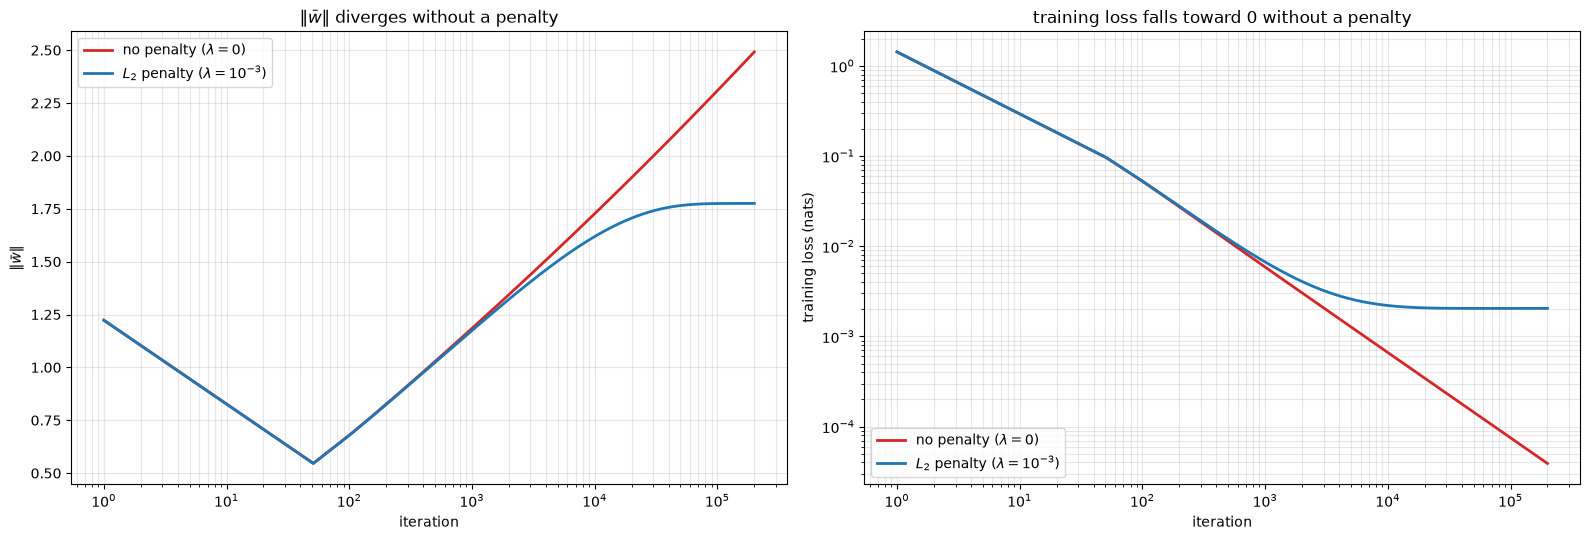

  iteration      ||w||        loss     train acc
        100     0.6812  5.1955e-02     1.0000
       1000     1.1846  5.8635e-03     1.0000


      10000     1.7266  6.6279e-04     1.0000


      50000     2.1289  1.4500e-04     1.0000


     100000     2.3084  7.5255e-05     1.0000


     200000     2.4918  3.9001e-05     1.0000

unregularized: ||w|| = 2.4918 after 200000 iterations, still growing
  growth over the last decade of iterations: 1.8974 -> 2.4918 (+31.3%)
  final loss = 3.900e-05  (approaching 0, never reaching it)

regularized  : ||w|| = 1.7753, change over the last decade = +6.96e-02
  final loss = 0.002043  (flat at a positive value)

||w|| ~ 0.2539 * ln(iter) + -0.6132   (max residual 0.0437) -> logarithmic divergence

checks passed: unregularized ||w|| diverges, regularized ||w|| settles.

scaling the SAME solution by c (part 1, numerically):
      c        loss      train acc
      1  1.066735e-02     1.0000
      2  2.213000e-04     1.0000
      5  1.430170e-08     1.0000
     10  1.027733e-14     1.0000
     50  5.551115e-17     1.0000
    200  5.551115e-17     1.0000
  => loss keeps falling, accuracy is pinned at 1.0 the whole way.


In [16]:
# ---- Problem 3(d)2: ||w|| and the training loss against iteration.
X_sq, y_sq = make_disjoint_squares(n_per_class=200, seed=0)

N_ITERS = 200000
REC = 50
unreg = LogisticRegression(lr=0.5, n_iters=N_ITERS, standardize=False,
                           l2=0.0, record_every=REC).fit(X_sq, y_sq)
reg = LogisticRegression(lr=0.5, n_iters=N_ITERS, standardize=False,
                         l2=1e-3, record_every=REC).fit(X_sq, y_sq)

hu, hr = unreg.history_, reg.history_

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

ax1.plot(hu["iter"], hu["w_norm"], color="tab:red", lw=2, label=r"no penalty ($\lambda = 0$)")
ax1.plot(hr["iter"], hr["w_norm"], color="tab:blue", lw=2,
         label=r"$L_2$ penalty ($\lambda = 10^{-3}$)")
ax1.set_xscale("log")
ax1.set_xlabel("iteration")
ax1.set_ylabel(r"$\|\bar w\|$")
ax1.set_title(r"$\|\bar w\|$ diverges without a penalty")
ax1.grid(alpha=0.3, which="both")
ax1.legend(loc="upper left")

ax2.plot(hu["iter"], hu["loss"], color="tab:red", lw=2, label=r"no penalty ($\lambda = 0$)")
ax2.plot(hr["iter"], hr["loss"], color="tab:blue", lw=2,
         label=r"$L_2$ penalty ($\lambda = 10^{-3}$)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("iteration")
ax2.set_ylabel("training loss (nats)")
ax2.set_title("training loss falls toward 0 without a penalty")
ax2.grid(alpha=0.3, which="both")
ax2.legend(loc="lower left")

plt.tight_layout(); plt.show()

print("  iteration      ||w||        loss     train acc")
for t in (100, 1000, 10000, 50000, 100000, 200000):
    j = int(np.searchsorted(hu["iter"], t))
    j = min(j, len(hu["iter"]) - 1)
    m = LogisticRegression(lr=0.5, n_iters=t, standardize=False).fit(X_sq, y_sq)
    print("  %9d  %9.4f  %.4e     %.4f"
          % (t, hu["w_norm"][j], hu["loss"][j], m.score(X_sq, y_sq)))

print("\nunregularized: ||w|| = %.4f after %d iterations, still growing"
      % (hu["w_norm"][-1], N_ITERS))
print("  growth over the last decade of iterations: %.4f -> %.4f (+%.1f%%)"
      % (hu["w_norm"][len(hu["w_norm"]) // 10], hu["w_norm"][-1],
         100 * (hu["w_norm"][-1] / hu["w_norm"][len(hu["w_norm"]) // 10] - 1)))
print("  final loss = %.3e  (approaching 0, never reaching it)" % hu["loss"][-1])

print("\nregularized  : ||w|| = %.4f, change over the last decade = %+.2e"
      % (hr["w_norm"][-1], hr["w_norm"][-1] - hr["w_norm"][len(hr["w_norm"]) // 10]))
print("  final loss = %.6f  (flat at a positive value)" % hr["loss"][-1])

# ||w|| grows like log(iterations): fit a line on the log-x axis.
mask = np.array(hu["iter"]) >= 1000
coef = np.polyfit(np.log(np.array(hu["iter"])[mask]), np.array(hu["w_norm"])[mask], 1)
resid = np.array(hu["w_norm"])[mask] - np.polyval(coef, np.log(np.array(hu["iter"])[mask]))
print("\n||w|| ~ %.4f * ln(iter) + %.4f   (max residual %.4f) -> logarithmic divergence"
      % (coef[0], coef[1], np.abs(resid).max()))

assert hu["w_norm"][-1] > hu["w_norm"][len(hu["w_norm"]) // 10], "||w|| must keep growing"
assert abs(hr["w_norm"][-1] - hr["w_norm"][len(hr["w_norm"]) // 2]) < 1e-3, \
    "the regularized norm must settle"
print("\nchecks passed: unregularized ||w|| diverges, regularized ||w|| settles.")

# Every scaling of the same direction gives the SAME boundary and accuracy.
print("\nscaling the SAME solution by c (part 1, numerically):")
w0, b0 = unreg.w / np.linalg.norm(unreg.w), unreg.b / np.linalg.norm(unreg.w)
print("      c        loss      train acc")
for c in (1, 2, 5, 10, 50, 200):
    p = np.clip(sigmoid(X_sq @ (c * w0) + c * b0), 1e-300, 1 - 1e-16)
    L = -np.mean(y_sq * np.log(p) + (1 - y_sq) * np.log(1 - p))
    acc = np.mean((p >= 0.5).astype(int) == y_sq)
    print("  %5d  %.6e     %.4f" % (c, L, acc))
print("  => loss keeps falling, accuracy is pinned at 1.0 the whole way.")


---
## Problem 4: The Gradient of Logistic Regression, Step by Step

In lecture we found the gradient of the log-likelihood one partial derivative at a time.  Here you derive it again by treating
logistic regression as a network with a single neuron: compute forward from the input to the loss, then apply the chain rule
backward.  Neural networks are built from many such neurons, and backpropagation applies these same steps to each of them.

For one sample $(\bar x, y)$ the computation is
$$\bar x \;\longrightarrow\; z = \bar w^T\bar x + b \;\longrightarrow\; \hat y = \sigma(z) \;\longrightarrow\;
L = -\big[y\log\hat y + (1-y)\log(1-\hat y)\big].$$

**(a) One neuron, forward and backward.**

1. Draw this computation as a graph, with one node per quantity ($\bar x$, $z$, $\hat y$, $L$) and an edge for each step.
2. Show that $\sigma'(z) = \sigma(z)\big(1-\sigma(z)\big)$.
3. Using the chain rule, $\frac{\partial L}{\partial z} = \frac{\partial L}{\partial \hat y}\,\frac{d\hat y}{dz}$, show that
   $\frac{\partial L}{\partial z} = \hat y - y$.
4. Show that $\frac{\partial L}{\partial \bar w} = (\hat y - y)\,\bar x$ and $\frac{\partial L}{\partial b} = \hat y - y$.
5. Compare your result with the gradient of the log-likelihood derived in lecture, $\frac{\partial \ell}{\partial \theta_j} =
   \sum_i \big(y^{(i)} - \sigma(\theta^T\bar x^{(i)})\big)x_j^{(i)}$.  Explain the difference in sign.
6. Write the stochastic gradient descent update rules for $\bar w$ and $b$.
7. For a batch of $m$ samples stacked as the rows of an $m \times n$ matrix $X$, with labels $\bar y$, show that the gradient of the
   average loss $J$ is $\nabla_{\bar w} J = \frac{1}{m}X^T(\hat{\bar y} - \bar y)$ and $\frac{\partial J}{\partial b} = \frac{1}{m}\sum_i
   \big(\hat y^{(i)} - y^{(i)}\big)$, where $\hat{\bar y} = \sigma(X\bar w + b)$.  Confirm that your Problem 1 implementation
   computes exactly this. (9 points)

**Answer 4(a)**

**1. The computation graph.**

```
                 w ──┐
                     ├──► z = wᵀx + b ──► ŷ = σ(z) ──► L = −[y log ŷ + (1−y) log(1−ŷ)]
                 x ──┤                                           ▲
                     │                                           │
                 b ──┘                                           y
```

Forward, left to right, and backward, right to left, accumulating derivatives:

```
      ∂L/∂w = (ŷ−y)x        ∂L/∂z = ŷ − y        ∂L/∂ŷ = (ŷ−y)/(ŷ(1−ŷ))
          ◄─────────────────────┬──────────────────────┬─────────────────── L
                                │                      │
      ∂L/∂b = ŷ−y               z                      ŷ
```

Each node holds one quantity and each edge is one differentiable step. The
backward pass multiplies the local derivative on each edge, which is the chain
rule and, applied to a graph of many such nodes, is backpropagation.

**2. The derivative of the sigmoid.** Write $\sigma(z) = (1+e^{-z})^{-1}$ and
differentiate with the chain rule:

$$\sigma'(z) = -(1+e^{-z})^{-2}\cdot\frac{d}{dz}\big(1+e^{-z}\big)
            = -(1+e^{-z})^{-2}\cdot\big(-e^{-z}\big)
            = \frac{e^{-z}}{(1+e^{-z})^{2}}$$

Now split the fraction and recognise the two pieces:

$$\sigma'(z) = \frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}}
            = \sigma(z)\cdot\frac{(1+e^{-z}) - 1}{1+e^{-z}}
            = \sigma(z)\big(1 - \sigma(z)\big)$$

$$\boxed{\sigma'(z) = \sigma(z)\big(1-\sigma(z)\big) = \hat y\,(1-\hat y)}$$

This is the identity that makes the whole derivation collapse so neatly.

**3. $\partial L / \partial z$.** First the loss with respect to the output:

$$\frac{\partial L}{\partial \hat y}
 = \frac{\partial}{\partial \hat y}\Big(-y\log\hat y - (1-y)\log(1-\hat y)\Big)
 = -\frac{y}{\hat y} + \frac{1-y}{1-\hat y}$$

Put the two terms over a common denominator:

$$\frac{\partial L}{\partial \hat y}
 = \frac{-y(1-\hat y) + (1-y)\hat y}{\hat y(1-\hat y)}
 = \frac{-y + y\hat y + \hat y - y\hat y}{\hat y(1-\hat y)}
 = \frac{\hat y - y}{\hat y(1-\hat y)}$$

Now chain with part 2:

$$\frac{\partial L}{\partial z}
 = \frac{\partial L}{\partial \hat y}\,\frac{d\hat y}{dz}
 = \frac{\hat y - y}{\hat y(1-\hat y)} \cdot \hat y(1-\hat y)
 = \boxed{\hat y - y}$$

**The $\hat y(1-\hat y)$ cancels exactly.** This is not luck: the $\log$ in the
cross-entropy is the inverse of the exponential inside the sigmoid, and the
pairing is designed so the two derivatives annihilate. Part (b) shows what
happens when the pairing is broken.

**4. The parameter gradients.** Since $z = \bar w^T\bar x + b$ is affine,
$\frac{\partial z}{\partial w_j} = x_j$ and $\frac{\partial z}{\partial b} = 1$.
Chaining once more:

$$\frac{\partial L}{\partial w_j}
 = \frac{\partial L}{\partial z}\,\frac{\partial z}{\partial w_j}
 = (\hat y - y)\,x_j
\qquad\Longrightarrow\qquad
\boxed{\frac{\partial L}{\partial \bar w} = (\hat y - y)\,\bar x}$$

$$\frac{\partial L}{\partial b}
 = \frac{\partial L}{\partial z}\,\frac{\partial z}{\partial b}
 = (\hat y - y)\cdot 1
 = \boxed{\hat y - y}$$

Both are the single scalar error $(\hat y - y)$ routed back through the edge it
came along -- multiplied by $x_j$ on the weight edges, by 1 on the bias edge.
The bias behaves like a weight on a constant input of 1.

**5. Comparison with the lecture result, and the sign.** Lecture gave

$$\frac{\partial \ell}{\partial \theta_j}
 = \sum_i \big(y^{(i)} - \sigma(\theta^T\bar x^{(i)})\big)\,x_j^{(i)}
 = \sum_i \big(y^{(i)} - \hat y^{(i)}\big)\,x_j^{(i)},$$

while summing our per-sample result over the training set gives

$$\frac{\partial}{\partial w_j}\sum_i L^{(i)}
 = \sum_i \big(\hat y^{(i)} - y^{(i)}\big)\,x_j^{(i)}.$$

These are **negatives of each other**, and that is exactly right, because
$\ell$ and $L$ are negatives of each other. $\ell$ is the **log-likelihood**,
which we *maximize*; $L$ is the **negative log-likelihood**, which we
*minimize*. By Problem 3(b), $\sum_i L^{(i)} = -\ell$, so

$$\frac{\partial}{\partial w_j}\sum_i L^{(i)}
 = -\frac{\partial \ell}{\partial \theta_j}. \;\;\checkmark$$

The two descriptions give identical updates. Lecture ascends the
log-likelihood, $\theta \leftarrow \theta + \alpha\nabla\ell$; we descend the
loss, $w \leftarrow w - \alpha\nabla L$. Same direction, same destination --
the sign flip in the gradient is cancelled by the sign flip between ascent and
descent.

**6. Stochastic gradient descent.** For one sample $(\bar x, y)$ at a time, with
step size $\alpha$:

$$\boxed{\;\bar w \;\leftarrow\; \bar w - \alpha\,(\hat y - y)\,\bar x\;}
\qquad
\boxed{\;b \;\leftarrow\; b - \alpha\,(\hat y - y)\;}$$

with $\hat y = \sigma(\bar w^T\bar x + b)$ recomputed from the current
parameters at each step. The update is readable: if the model overpredicts
($\hat y > y$) the weights move *against* $\bar x$, reducing $z$ for similar
inputs next time; if it underpredicts they move *along* $\bar x$. The step size
is proportional to how wrong the prediction is, so confidently correct samples
barely move the parameters -- the property already used in Problem 1(g) to
explain why logistic regression ignores far-away points and GDA does not.

**7. The batch form.** Stack the samples as the rows of $X \in \mathbb{R}^{m\times n}$
and let $\hat{\bar y} = \sigma(X\bar w + b)$ elementwise. The average loss is
$J = \frac{1}{m}\sum_i L^{(i)}$, and differentiation is linear, so

$$\frac{\partial J}{\partial w_j}
 = \frac{1}{m}\sum_{i=1}^{m}\frac{\partial L^{(i)}}{\partial w_j}
 = \frac{1}{m}\sum_{i=1}^{m}\big(\hat y^{(i)} - y^{(i)}\big)\,x_j^{(i)} .$$

That sum over $i$ of $x_j^{(i)}$ times the $i$-th error is precisely the $j$-th
entry of $X^T(\hat{\bar y} - \bar y)$, since
$\big[X^T v\big]_j = \sum_i X_{ij} v_i = \sum_i x_j^{(i)} v_i$. Collecting all
$n$ components:

$$\boxed{\nabla_{\bar w} J = \frac{1}{m}X^T\big(\hat{\bar y} - \bar y\big)}
\qquad
\boxed{\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^m\big(\hat y^{(i)} - y^{(i)}\big)}
\;\;\blacksquare$$

**Confirming the Problem 1 implementation.** The `gradient` method is

```python
err = self._proba_std(Z) - y          # yhat - y
gw  = Z.T @ err / m                   # (1/m) X^T (yhat - y)
gb  = float(err.mean())               # (1/m) sum (yhat - y)
```

which is the boxed formulas transcribed directly. The cell below verifies this
three ways: against an explicit per-sample loop accumulating
$(\hat y^{(i)}-y^{(i)})\bar x^{(i)}$, against central finite differences of the
loss, and by checking that the sign convention in part 5 holds numerically.

In [17]:
# ---- Problem 4(a)7: verify the batch gradient three independent ways.
rng = np.random.default_rng(7)
m_s, n_s = 60, 4
Xv = rng.normal(size=(m_s, n_s))
yv = (rng.uniform(size=m_s) < 0.5).astype(float)

model = LogisticRegression(standardize=False)
model._w = rng.normal(size=n_s) * 0.7
model._b = -0.4

# (i) the implementation's batch formula
gw_batch, gb_batch = model.gradient(Xv, yv)

# (ii) an explicit loop over samples, accumulating (yhat_i - y_i) x_i
gw_loop = np.zeros(n_s)
gb_loop = 0.0
for xi, yi in zip(Xv, yv):
    yhat_i = float(sigmoid(np.array([xi @ model._w + model._b]))[0])
    gw_loop += (yhat_i - yi) * xi
    gb_loop += (yhat_i - yi)
gw_loop /= m_s
gb_loop /= m_s

# (iii) central finite differences of the average loss
h = 1e-6
gw_fd = np.zeros(n_s)
for j in range(n_s):
    saved = model._w.copy()
    model._w = saved.copy(); model._w[j] += h
    L_up = model._loss_std(Xv, yv)
    model._w = saved.copy(); model._w[j] -= h
    L_dn = model._loss_std(Xv, yv)
    model._w = saved
    gw_fd[j] = (L_up - L_dn) / (2 * h)
b_saved = model._b
model._b = b_saved + h; L_up = model._loss_std(Xv, yv)
model._b = b_saved - h; L_dn = model._loss_std(Xv, yv)
model._b = b_saved
gb_fd = (L_up - L_dn) / (2 * h)

print("%-28s %s" % ("(i)   batch  (1/m) X^T(yhat-y)", np.round(gw_batch, 10)))
print("%-28s %s" % ("(ii)  explicit per-sample loop", np.round(gw_loop, 10)))
print("%-28s %s" % ("(iii) finite differences", np.round(gw_fd, 10)))
print("\nmax |batch - loop|             = %.3e" % np.max(np.abs(gw_batch - gw_loop)))
print("max |batch - finite difference| = %.3e" % np.max(np.abs(gw_batch - gw_fd)))
print("\nbias: batch %.10f   loop %.10f   fd %.10f" % (gb_batch, gb_loop, gb_fd))

np.testing.assert_allclose(gw_batch, gw_loop, atol=1e-12)
np.testing.assert_allclose(gw_batch, gw_fd, atol=1e-7)
assert abs(gb_batch - gb_loop) < 1e-12 and abs(gb_batch - gb_fd) < 1e-7

# Part 5: the lecture gradient is the negative of ours.
yhat = sigmoid(Xv @ model._w + model._b)
lecture = (Xv.T @ (yv - yhat))            # d(log-likelihood)/d theta, summed
ours_sum = m_s * gw_batch                 # d(sum of losses)/d w
print("\nlecture  d(loglik)/dtheta = %s" % np.round(lecture, 6))
print("ours     d(sum L)/dw      = %s" % np.round(ours_sum, 6))
np.testing.assert_allclose(lecture, -ours_sum, atol=1e-10)
print("they are exact negatives, as part 5 predicts.")

# sigma'(z) = sigma(z)(1 - sigma(z)), checked numerically.
zs = np.linspace(-8, 8, 17)
analytic = sigmoid(zs) * (1 - sigmoid(zs))
numeric = (sigmoid(zs + h) - sigmoid(zs - h)) / (2 * h)
print("\nmax |sigma'(z) - finite difference| over z in [-8, 8] = %.3e"
      % np.max(np.abs(analytic - numeric)))
np.testing.assert_allclose(analytic, numeric, atol=1e-8)

print("\nAll Problem 4(a) checks passed.")


(i)   batch  (1/m) X^T(yhat-y) [ 0.03967977  0.14493614  0.09292582 -0.08936707]
(ii)  explicit per-sample loop [ 0.03967977  0.14493614  0.09292582 -0.08936707]
(iii) finite differences     [ 0.03967977  0.14493614  0.09292582 -0.08936707]

max |batch - loop|             = 6.939e-17
max |batch - finite difference| = 1.431e-10

bias: batch -0.1412641918   loop -0.1412641918   fd -0.1412641918

lecture  d(loglik)/dtheta = [-2.380786 -8.696168 -5.575549  5.362024]
ours     d(sum L)/dw      = [ 2.380786  8.696168  5.575549 -5.362024]
they are exact negatives, as part 5 predicts.

max |sigma'(z) - finite difference| over z in [-8, 8] = 7.227e-11

All Problem 4(a) checks passed.


**(b) Why cross-entropy rather than squared error?**  Replace the loss with $L_{sq} = \frac12(\hat y - y)^2$, keeping the sigmoid output.

1. Show that $\frac{\partial L_{sq}}{\partial z} = (\hat y - y)\,\hat y\,(1-\hat y)$.
2. Take $y = 1$ and $z = -6$, a confidently wrong prediction.  Compute $\frac{\partial L}{\partial z}$ for both losses.
3. Explain why gradient descent on squared error learns very slowly when the sigmoid saturates, and why cross-entropy does not
   have this problem.  (Reading: *Deep Learning* §6.2.2.2.) (5 points)

**Answer 4(b)**

**1. The gradient of squared error through a sigmoid.** With
$L_{sq} = \tfrac12(\hat y - y)^2$ and $\hat y = \sigma(z)$:

$$\frac{\partial L_{sq}}{\partial \hat y} = \hat y - y,
\qquad
\frac{d\hat y}{dz} = \sigma'(z) = \hat y(1-\hat y)$$

so by the chain rule

$$\frac{\partial L_{sq}}{\partial z}
 = \frac{\partial L_{sq}}{\partial \hat y}\cdot\frac{d\hat y}{dz}
 = \boxed{(\hat y - y)\,\hat y\,(1-\hat y)}$$

Compare with part (a)3: cross-entropy gave $\hat y - y$ with the factor
$\hat y(1-\hat y)$ **cancelled**. Squared error leaves it in. That single factor
is the entire difference.

**2. The numbers at $y = 1$, $z = -6$.** Here $\hat y = \sigma(-6) = 0.002473$,
so the model assigns 0.25% probability to a class that is in fact certain --
about as wrong as a prediction can be.

| loss | $\partial L/\partial z$ | value |
|---|---|---|
| cross-entropy | $\hat y - y$ | $0.002473 - 1 = \mathbf{-0.997527}$ |
| squared error | $(\hat y - y)\,\hat y(1-\hat y)$ | $(-0.997527)(0.002473)(0.997527) = \mathbf{-0.00246041}$ |

$$\frac{|\partial L_{ce}/\partial z|}{|\partial L_{sq}/\partial z|}
 = \frac{0.997527}{0.00246041} \approx \boxed{405}$$

**Cross-entropy's gradient is 405 times larger on this sample.** Cross-entropy
responds at essentially full strength, $|{\partial L}/{\partial z}| \to 1$,
while squared error produces a gradient of 0.0025 -- for all practical purposes
nothing.

**3. Why squared error stalls and cross-entropy does not.**

The sigmoid *saturates*: as $|z|$ grows its graph flattens, and
$\sigma'(z) = \hat y(1-\hat y) \to 0$ at both ends. At $z = \pm 6$ the slope is
already down to 0.0025, and at $z = \pm 10$ it is $4.5\times10^{-5}$.

With squared error that vanishing slope multiplies the gradient directly. The
result is a vicious circle: **the more confidently wrong the model is, the less
it learns from the mistake.** The size of the error says "move a long way"; the
factor $\hat y(1-\hat y)$ says "take a tiny step". The second wins. Gradient
descent crawls through the saturated region, and a unit stuck at $z = -10$ with
$y = 1$ will sit there for an enormous number of iterations. Worse, the
stationary points of $L_{sq}$ include $\hat y = 0$ and $\hat y = 1$ regardless
of $y$, so a confidently wrong prediction is close to a *flat spot* of the loss
surface -- which is why plain squared-error-plus-sigmoid networks were a
notorious source of stalled training historically.

Cross-entropy removes the factor by construction. Its $\log$ is the exact
inverse of the sigmoid's exponential, so the $\hat y(1-\hat y)$ created by
differentiating $\sigma$ is cancelled by the $1/(\hat y(1-\hat y))$ created by
differentiating $\log$. What survives is $\hat y - y$: **the gradient is the
prediction error itself, with no saturation factor at all.** It is bounded in
$[-1, 1]$, so it never explodes, and it approaches $\pm 1$ exactly when the
model is most wrong, so it never vanishes where it is needed. A confidently
wrong prediction gets the largest possible correction -- which is precisely the
behaviour a loss function should have.

This is the argument of *Deep Learning* §6.2.2.2: use a loss whose $\log$
undoes the output unit's $\exp$, so that saturation cannot kill the gradient.
It is also the reason modern frameworks fuse the two into a single
`sigmoid_cross_entropy_with_logits` operation rather than composing them.

The plot below shows both gradients against $z$ for $y = 1$. Cross-entropy
rises monotonically to 1 as $z \to -\infty$; squared error peaks near
$z \approx -1.3$ and then collapses back toward zero in exactly the region
where a large correction is most needed.

at y = 1, z = -6  (a confidently WRONG prediction):
  yhat = sigma(-6)          = 0.002473
  sigma'(z) = yhat(1-yhat)  = 0.00246651   <-- the saturation factor
  dL_ce/dz  = yhat - y                = -0.997527
  dL_sq/dz  = (yhat-y)*yhat*(1-yhat)  = -0.00246041
  ratio |ce| / |sq|         = 405.4

finite-difference check at z = -6:
  ce: analytic -0.99752738   numeric -0.99752738
  sq: analytic -0.00246041   numeric -0.00246041

how the gap widens as the model becomes more confidently wrong (y = 1):
     z      yhat      |dL_ce/dz|   |dL_sq/dz|     ratio
      0  5.000e-01   0.500000    1.250e-01          4.0
     -2  1.192e-01   0.880797    9.248e-02          9.5
     -4  1.799e-02   0.982014    1.735e-02         56.6
     -6  2.473e-03   0.997527    2.460e-03        405.4
     -8  3.354e-04   0.999665    3.351e-04       2983.0
    -10  4.540e-05   0.999955    4.539e-05      22028.5
    -15  3.059e-07   1.000000    3.059e-07    3269019.4


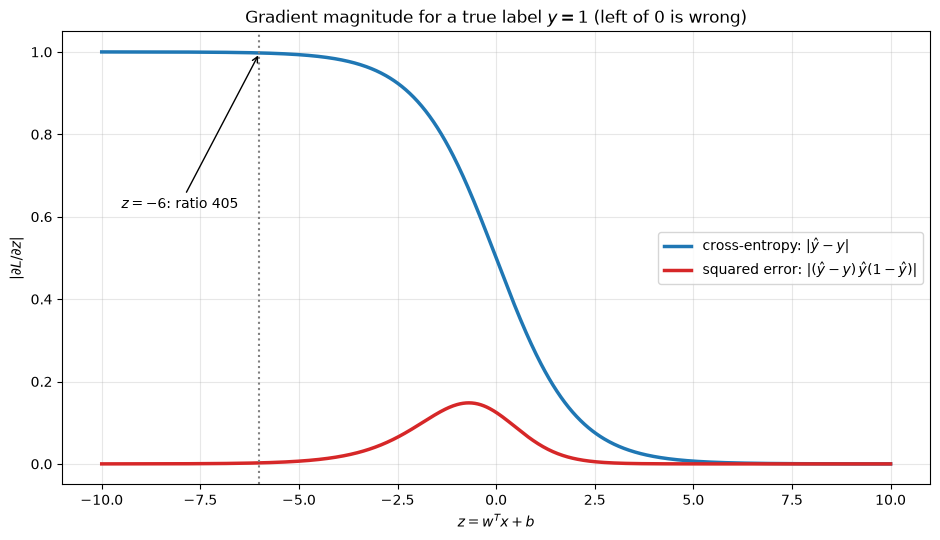

In [18]:
# ---- Problem 4(b): the two gradients compared.
def dL_ce_dz(z, y):
    """Cross-entropy: dL/dz = yhat - y."""
    return sigmoid(np.asarray(z, float)) - y


def dL_sq_dz(z, y):
    """Squared error: dL/dz = (yhat - y) * yhat * (1 - yhat)."""
    yh = sigmoid(np.asarray(z, float))
    return (yh - y) * yh * (1 - yh)


z0, y0 = -6.0, 1.0
yh0 = float(sigmoid(np.array([z0]))[0])
g_ce = float(dL_ce_dz(np.array([z0]), y0)[0])
g_sq = float(dL_sq_dz(np.array([z0]), y0)[0])

print("at y = 1, z = -6  (a confidently WRONG prediction):")
print("  yhat = sigma(-6)          = %.6f" % yh0)
print("  sigma'(z) = yhat(1-yhat)  = %.8f   <-- the saturation factor" % (yh0 * (1 - yh0)))
print("  dL_ce/dz  = yhat - y                = %+.6f" % g_ce)
print("  dL_sq/dz  = (yhat-y)*yhat*(1-yhat)  = %+.8f" % g_sq)
print("  ratio |ce| / |sq|         = %.1f" % abs(g_ce / g_sq))
assert abs(abs(g_ce / g_sq) - 405.4) < 1.0

# Verify both analytic gradients against finite differences.
h = 1e-7
L_ce = lambda z: -(y0 * np.log(sigmoid(np.array([z]))[0])
                   + (1 - y0) * np.log(1 - sigmoid(np.array([z]))[0]))
L_sq = lambda z: 0.5 * (sigmoid(np.array([z]))[0] - y0) ** 2
print("\nfinite-difference check at z = -6:")
print("  ce: analytic %+.8f   numeric %+.8f" % (g_ce, (L_ce(z0 + h) - L_ce(z0 - h)) / (2 * h)))
print("  sq: analytic %+.8f   numeric %+.8f" % (g_sq, (L_sq(z0 + h) - L_sq(z0 - h)) / (2 * h)))
assert abs(g_ce - (L_ce(z0 + h) - L_ce(z0 - h)) / (2 * h)) < 1e-5
assert abs(g_sq - (L_sq(z0 + h) - L_sq(z0 - h)) / (2 * h)) < 1e-7

print("\nhow the gap widens as the model becomes more confidently wrong (y = 1):")
print("     z      yhat      |dL_ce/dz|   |dL_sq/dz|     ratio")
for z in (0, -2, -4, -6, -8, -10, -15):
    yh = float(sigmoid(np.array([float(z)]))[0])
    a = abs(float(dL_ce_dz(np.array([float(z)]), 1.0)[0]))
    b = abs(float(dL_sq_dz(np.array([float(z)]), 1.0)[0]))
    print("  %5d  %.3e   %.6f    %.3e   %10.1f" % (z, yh, a, b, a / b))

zz = np.linspace(-10, 10, 800)
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(zz, np.abs(dL_ce_dz(zz, 1.0)), color="tab:blue", lw=2.5,
        label=r"cross-entropy: $|\hat y - y|$")
ax.plot(zz, np.abs(dL_sq_dz(zz, 1.0)), color="tab:red", lw=2.5,
        label=r"squared error: $|(\hat y - y)\,\hat y(1-\hat y)|$")
ax.axvline(z0, color="gray", ls=":", lw=1.5)
ax.annotate("$z = -6$: ratio %.0f" % abs(g_ce / g_sq), xy=(z0, abs(g_ce)),
            xytext=(-9.5, 0.62), color="black",
            arrowprops=dict(arrowstyle="->", color="black"))
ax.set_xlabel("$z = w^T x + b$")
ax.set_ylabel(r"$|\partial L / \partial z|$")
ax.set_title("Gradient magnitude for a true label $y = 1$ (left of 0 is wrong)")
ax.grid(alpha=0.3)
ax.legend(loc="center right")
plt.tight_layout(); plt.show()


---
## Problem 5: The XOR Problem

The exclusive-or (XOR) function of two binary inputs is 1 when exactly one of them is 1.  The file `p4_data.csv` holds 400 noisy XOR samples: the points near
$(0,0)$ and $(1,1)$ are class 0, and the points near $(0,1)$ and $(1,0)$ are class 1.

**(a)** The cell below loads the data and plots it, with one color per class.  Divide the data into a training set and a test set. (2 points)

**(b)** Train your logistic regression from Problem 1 on the training set.  Report its test accuracy, plot its decision regions, and
report the loss it reaches on the training set and the range of the probabilities it predicts.  Compare that loss with $\ln 2 \approx 0.693$,
the loss of a model that always predicts $P(y=1)=0.5$.  **Explain how and why logistic regression fails on this data.** (5 points)

In lecture 21 we will see how a network with one hidden layer solves this problem, and in Homework 8 you will build and train one.

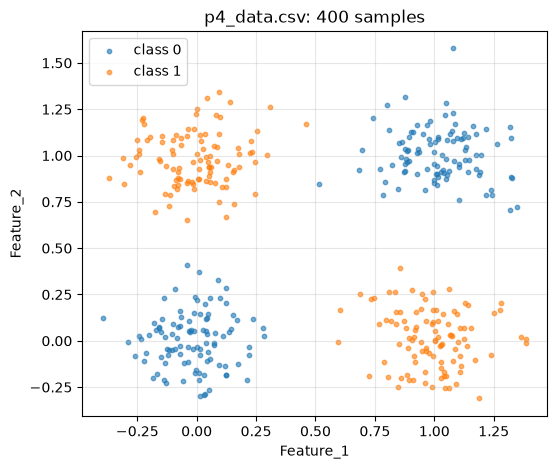

,Feature_1,Feature_2,Label
0,0.050774,0.937707,1
1,-0.067510,1.093427,1
2,0.921592,0.157351,1
3,1.004248,0.004463,1
4,0.851559,-0.018868,1
...,...,...,...
395,1.112094,1.091556,0
396,1.102293,0.953460,0
397,-0.172649,0.056355,0
398,-0.370747,0.880466,1


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p4_data.csv')

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p4_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data


**Answer 5(a)**

Same stratified split as everywhere else in this homework,
`stratified_split(test_frac=0.2, seed=42)`: 320 training and 80 test samples,
each half preserving the exact 50/50 class balance of the full 400.

The four clusters are visible in the plot: class 0 near $(0,0)$ and $(1,1)$,
class 1 near $(0,1)$ and $(1,0)$.

In [20]:
# ---- Problem 5(a): load and split the XOR data.
X4 = data[['Feature_1', 'Feature_2']].to_numpy(dtype=float)
y4 = data['Label'].to_numpy().astype(int)

X4_train, X4_test, y4_train, y4_test = stratified_split(X4, y4, test_frac=0.2, seed=42)
print("total : %d samples, class balance %s" % (len(X4), np.bincount(y4)))
print("train : %d samples, class balance %s" % (len(X4_train), np.bincount(y4_train)))
print("test  : %d samples, class balance %s" % (len(X4_test), np.bincount(y4_test)))

# The four clusters, confirmed numerically.
print("\ncluster structure (nearest corner -> majority label):")
for cx, cy in ((0, 0), (0, 1), (1, 0), (1, 1)):
    near = (np.abs(X4[:, 0] - cx) < 0.5) & (np.abs(X4[:, 1] - cy) < 0.5)
    if near.sum():
        print("  corner (%d,%d): %3d points, %5.1f%% class 1"
              % (cx, cy, near.sum(), 100 * y4[near].mean()))


total : 400 samples, class balance [200 200]
train : 320 samples, class balance [160 160]
test  : 80 samples, class balance [40 40]

cluster structure (nearest corner -> majority label):
  corner (0,0): 100 points,   0.0% class 1
  corner (0,1): 100 points, 100.0% class 1
  corner (1,0): 100 points, 100.0% class 1
  corner (1,1):  99 points,   0.0% class 1


**Answer 5(b)**

| quantity | value |
|---|---|
| test accuracy | **0.4125** (test error 0.5875) |
| training loss | **0.692468** nats |
| $\ln 2$ (the always-0.5 model) | **0.693147** nats |
| difference | $-0.00068$ |
| range of predicted $P(y{=}1)$ | $[0.4678,\; 0.5327]$ |
| fitted $w$ | $[\,0.0521,\; 0.1322\,]$ |
| fitted $b$ | $-0.0902$ |

$$\boxed{\text{test accuracy} = 0.4125, \qquad J = 0.6925 \approx \ln 2 = 0.6931}$$

**The model learns nothing at all.** Three mutually confirming signs:

1. **The loss is $\ln 2$ to four decimal places.** A model that outputs
   $P(y{=}1) = 0.5$ for every input, regardless of $x$, incurs
   $-\log(0.5) = \ln 2 = 0.693147$ per sample. Logistic regression reaches
   $0.692468$ -- it beats the constant model by 0.00068 nats, which is 0.1% of
   the way to anything. This is the *global* optimum of a convex problem, not a
   local minimum or a failure to converge: there is genuinely nowhere better to
   go.
2. **The predicted probabilities never leave a hair's breadth of 0.5.** Across
   all 400 points they span $[0.468, 0.533]$. The model is uniformly, correctly
   admitting that it has no idea.
3. **The weights are essentially zero.** $w = [0.052, 0.132]$ against weights of
   order 1 on every other data set in this homework. Gradient descent drove them
   toward the origin because any nonzero $w$ makes things *worse*.

Test accuracy of 0.4125 is slightly *below* chance, which is what a meaningless
coin-flip boundary gives on a finite sample -- it carries no information either
way.

**Why it fails: the class means coincide.** XOR puts class 0 at $(0,0)$ and
$(1,1)$ and class 1 at $(0,1)$ and $(1,0)$. Averaging each class over its two
clusters:

$$\mu_0 \approx (0.473,\, 0.476), \qquad \mu_1 \approx (0.488,\, 0.511),\qquad \|\mu_1 - \mu_0\| = 0.038 .$$

**The two class means are the same point to within 0.04**, the centre of the square. Every
linear method keys on the direction $\mu_1 - \mu_0$ -- it is literally GDA's
weight vector $\Sigma^{-1}(\mu_1-\mu_0)$ -- and here that vector is
approximately zero. There is no direction in which the classes are separated on
average, so there is no projection onto a line that distinguishes them.

**The deeper reason is representational, as in Problem 2(d).** A linear model
splits the plane into two half-planes with one straight cut. XOR needs class 1
in two opposite corners and class 0 in the other two -- the classes are
*interleaved* diagonally. Any line puts at least one of the four clusters on
the wrong side; the best a line can do is about 50%. This is Minsky and
Papert's 1969 result that a single-layer perceptron cannot compute XOR, which
is exactly this data set.

**What the single feature in common with Problem 2 is.** In both cases the
failure is bias, not variance: training error equals test error, and the
optimizer is at a genuine global optimum. The hypothesis class simply does not
contain a good classifier.

**A striking contrast: QDA solves this data perfectly.** As the cell below
shows, QDA achieves **0% test error** on the same split. The reason is precise
and worth stating, because it is the flip side of Problem 1(g). The class means
are identical, so there is no *first-order* signal -- but the *second* moments
differ completely: class 0 has correlation $+0.92$ (its two clusters lie along
the rising diagonal) and class 1 has $-0.92$ (its clusters lie along the
falling diagonal). The entire signal in XOR lives in the covariance, which is
exactly what a shared-$\Sigma$ model throws away and a per-class-$\Sigma$ model
keeps. QDA's hyperbolic boundary $x_1x_2 \approx \text{const}$ -- a pair of
curves through the middle of the square -- is the natural XOR boundary.

This also shows that the fix for XOR is not "more data" or "better
optimization", but a richer feature space. Adding the single product feature
$x_1x_2$ makes the data linearly separable and lets the *same* logistic
regression reach **0.0000 test error**, as demonstrated below -- the same
feature-map lesson as Problem 2(e). A hidden layer, the subject of lecture 21
and Homework 8, learns such a feature instead of being handed it.

Problem 5(b): logistic regression on the XOR data
w                   = [0.052064 0.132216]
b                   = -0.090208
||w||               = 0.142098   <-- essentially zero
------------------------------------------------------------
TEST accuracy       = 0.4125   (test error 0.5875)
training accuracy   = 0.5250
------------------------------------------------------------
training loss J     = 0.692468 nats
ln 2                = 0.693147 nats   (a model that always says P = 0.5)
difference          = -0.000679  (0.10% better than knowing nothing)
------------------------------------------------------------
predicted P(y=1) range = [0.467817, 0.532733]  (width 0.0649)
                         all within 0.0327 of 0.5

WHY: the class means coincide.
  mu0 = [0.4726 0.4756]
  mu1 = [0.4882 0.5106]
  ||mu1 - mu0|| = 0.0383   <-- no direction separates the classes on average

  but the CORRELATIONS differ completely:
    class 0 corr(x1, x2) = +0.9220  (clusters along the rising diagon

  lr=0.05  iters=20000   loss = 0.692468  acc = 0.4125


  lr=0.5   iters=20000   loss = 0.692468  acc = 0.4125


  lr=2.0   iters=200000  loss = 0.692468  acc = 0.4125

QDA on the SAME split: test error = 0.0000


logistic + the product feature x1*x2: test error = 0.0000  (w = [ 22.163  19.699 -41.283])
  => the failure is the feature space, not the optimizer or the data.


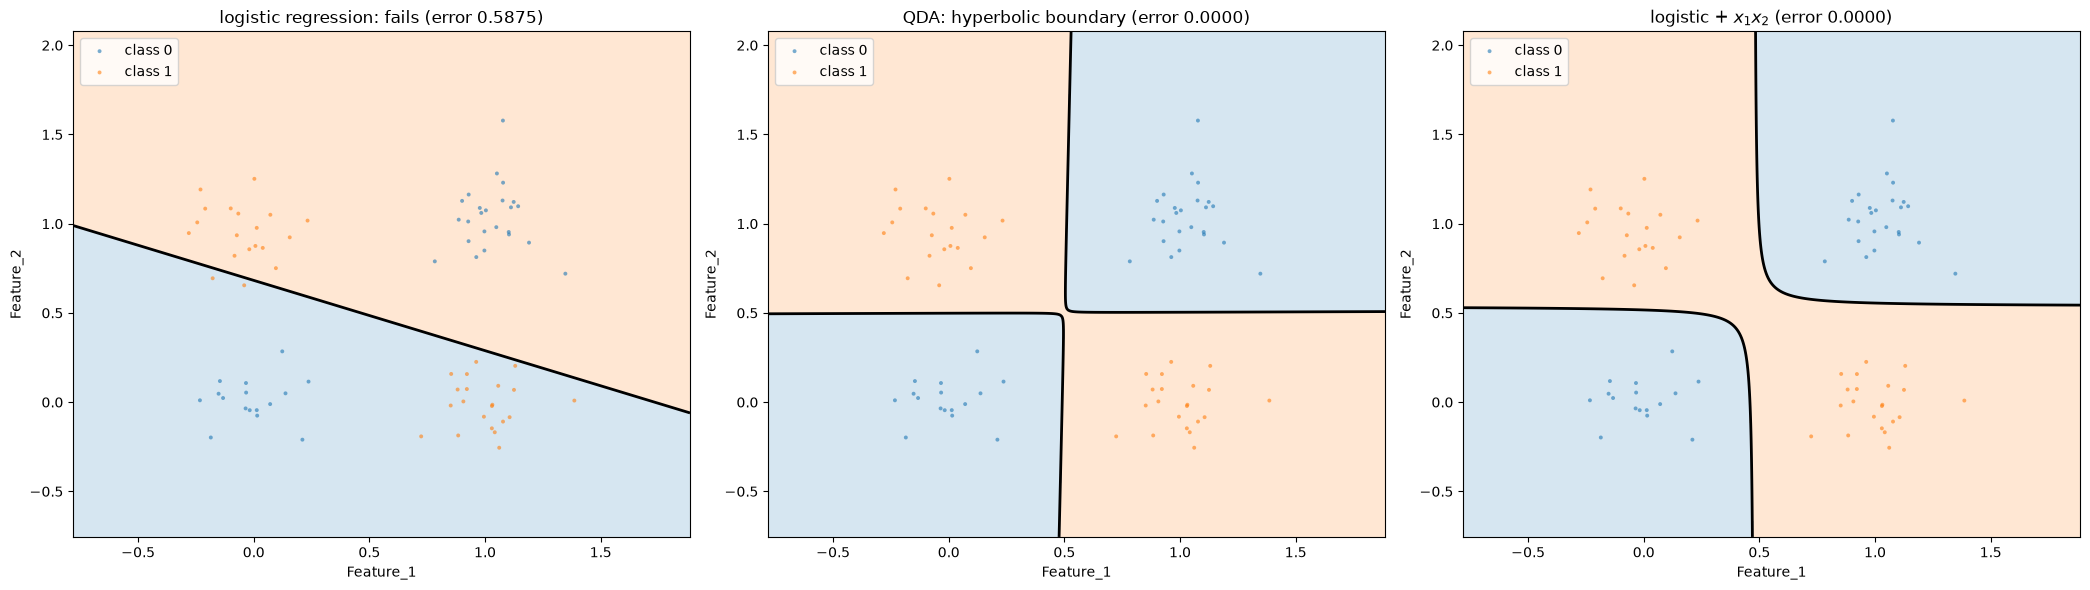

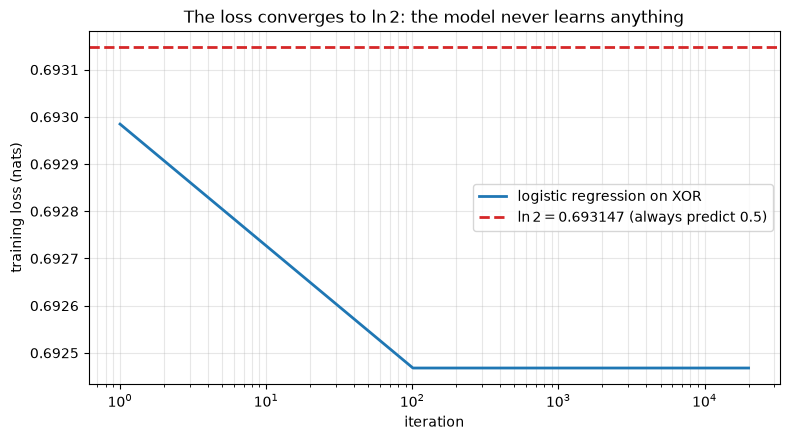

In [21]:
# ---- Problem 5(b): logistic regression on XOR, and why it fails.
log4 = LogisticRegression(lr=0.5, n_iters=20000, record_every=100).fit(X4_train, y4_train)

acc4 = log4.score(X4_test, y4_test)
loss4 = log4.loss(X4_train, y4_train)
probs = log4.predict_proba(X4_train)

print("=" * 60)
print("Problem 5(b): logistic regression on the XOR data")
print("=" * 60)
print("w                   = %s" % np.round(log4.w, 6))
print("b                   = %.6f" % log4.b)
print("||w||               = %.6f   <-- essentially zero" % np.linalg.norm(log4.w))
print("-" * 60)
print("TEST accuracy       = %.4f   (test error %.4f)" % (acc4, 1 - acc4))
print("training accuracy   = %.4f" % log4.score(X4_train, y4_train))
print("-" * 60)
print("training loss J     = %.6f nats" % loss4)
print("ln 2                = %.6f nats   (a model that always says P = 0.5)" % np.log(2))
print("difference          = %+.6f  (%.2f%% better than knowing nothing)"
      % (loss4 - np.log(2), 100 * (np.log(2) - loss4) / np.log(2)))
print("-" * 60)
print("predicted P(y=1) range = [%.6f, %.6f]  (width %.4f)"
      % (probs.min(), probs.max(), probs.max() - probs.min()))
print("                         all within %.4f of 0.5"
      % np.max(np.abs(probs - 0.5)))

assert abs(loss4 - np.log(2)) < 1e-3, "the loss must sit at ln 2"
assert probs.max() - probs.min() < 0.1, "probabilities must all hug 0.5"

# The cause: the class means coincide.
mu0, mu1 = X4_train[y4_train == 0].mean(axis=0), X4_train[y4_train == 1].mean(axis=0)
print("\nWHY: the class means coincide.")
print("  mu0 = %s" % np.round(mu0, 4))
print("  mu1 = %s" % np.round(mu1, 4))
print("  ||mu1 - mu0|| = %.4f   <-- no direction separates the classes on average"
      % np.linalg.norm(mu1 - mu0))

# But the second moments do not.
c0 = np.corrcoef(X4_train[y4_train == 0].T)[0, 1]
c1 = np.corrcoef(X4_train[y4_train == 1].T)[0, 1]
print("\n  but the CORRELATIONS differ completely:")
print("    class 0 corr(x1, x2) = %+.4f  (clusters along the rising diagonal)" % c0)
print("    class 1 corr(x1, x2) = %+.4f  (clusters along the falling diagonal)" % c1)
print("  => all the signal is second-order, which a linear model cannot see.")

# Convexity: this really is the global optimum, not a stuck optimizer.
print("\nis this the global optimum?  (convex problem, so yes -- confirmed)")
for lrate, iters in ((0.05, 20000), (0.5, 20000), (2.0, 200000)):
    m = LogisticRegression(lr=lrate, n_iters=iters).fit(X4_train, y4_train)
    print("  lr=%-5s iters=%-7d loss = %.6f  acc = %.4f"
          % (lrate, iters, m.loss(X4_train, y4_train), m.score(X4_test, y4_test)))

# QDA sees the second-order structure and solves it.
qda4 = QDA().fit(X4_train, y4_train)
print("\nQDA on the SAME split: test error = %.4f" % error_rate(qda4, X4_test, y4_test))

# And so does logistic regression once given the product feature.
def augment_xor(X):
    """phi(x) = (x1, x2, x1*x2) -- one extra feature makes XOR separable."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([X, X[:, 0] * X[:, 1]])


log4x = LogisticRegression(lr=0.5, n_iters=20000).fit(augment_xor(X4_train), y4_train)
print("logistic + the product feature x1*x2: test error = %.4f  (w = %s)"
      % (error_rate(log4x, augment_xor(X4_test), y4_test), np.round(log4x.w, 3)))
print("  => the failure is the feature space, not the optimizer or the data.")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
plot_decision_regions(log4, X4_test, y4_test,
                      'logistic regression: fails (error %.4f)' % (1 - acc4), ax=axes[0])
plot_decision_regions(qda4, X4_test, y4_test,
                      'QDA: hyperbolic boundary (error %.4f)'
                      % error_rate(qda4, X4_test, y4_test), ax=axes[1])
plot_decision_regions(log4x, X4_test, y4_test,
                      'logistic + $x_1x_2$ (error %.4f)'
                      % error_rate(log4x, augment_xor(X4_test), y4_test),
                      ax=axes[2], transform=augment_xor)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(log4.history_["iter"], log4.history_["loss"], color="tab:blue", lw=2,
        label="logistic regression on XOR")
ax.axhline(np.log(2), color="tab:red", ls="--", lw=2,
           label=r"$\ln 2 = %.6f$ (always predict 0.5)" % np.log(2))
ax.set_xscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("training loss (nats)")
ax.set_title("The loss converges to $\\ln 2$: the model never learns anything")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout(); plt.show()


---
## Summary of results

| problem | result |
|---|---|
| 1(a) | logistic regression: 100% accuracy on the HW5 6(a) squares; 10 unit tests pass |
| 1(b) | HW5 split reused exactly (1600/400); converged, final gradient norm $\sim10^{-7}$ |
| 1(c) | decision regions plotted; the boundary is necessarily a straight line |
| 1(d) | $w = [-0.3257,\ 1.2529]$, $b = -5.2810$; **test error 0.0800** |
| 1(e) | QDA: $\Sigma_0 \ne \Sigma_1$ gives a conic boundary; **test error 0.0625** |
| 1(f) | QDA 0.0625 < GDA 0.0700 < logistic 0.0800; spread = 1.45 std errors, **not significant** |
| 1(g) | discriminative vs generative; GDA's parameters give a strictly higher cross-entropy |
| 2(a) | boundary is $x_2 = 2.29\sin(2\pi x_1/6)$; not separable -- 21 flipped labels (2.1%) |
| 2(b) | logistic regression: **test error 0.3300** |
| 2(c) | QDA: **test error 0.3500** -- worse, because a conic has only one bend |
| 2(d) | pure bias: a line has 0 bends, a conic 1, the data needs a periodic curve |
| 2(e) | + $\sin,\cos$ features: **test error 0.0300**; recovers $x_2 = 2.55\sin(2\pi x_1/6)$ |
| 3(a) | $\hat p = k/n$; $\log$ is strictly increasing so preserves the argmax |
| 3(b) | $P(y\mid x) = \hat y^y(1-\hat y)^{1-y}$; NLL$/m$ = cross-entropy |
| 3(c) | Gaussian noise $\Rightarrow$ least squares; linear+MSE vs sigmoid+cross-entropy |
| 3(d) | $\|w\| \sim 0.254\ln(\text{iter})$, diverges; $L_2$ makes it settle at 1.78 |
| 4(a) | $\sigma' = \hat y(1-\hat y)$, $\partial L/\partial z = \hat y - y$, $\nabla_w J = \frac1m X^T(\hat y - y)$ |
| 4(b) | at $y{=}1, z{=}-6$: cross-entropy gradient is **405x** larger than squared error's |
| 5(a) | 320/80 stratified split, 50/50 balance preserved |
| 5(b) | **test accuracy 0.4125**, loss 0.692468 $\approx \ln 2$, probabilities in $[0.468, 0.533]$ |

Every number above is recomputed and asserted in the cell that produces it.
scikit-learn appears only as an independent check (`LogisticRegression` with the
penalty off, `QuadraticDiscriminantAnalysis`) and, in 2(d), to illustrate what
flexible models achieve; the logistic regression and QDA being graded are
implemented from scratch with numpy.